<h1>TAKE HOME TEST PROJECT ASSIGNMENT</h1>
<H2>Analisis Retail FMCG Sales</H2>

<h3>A. Import Library</h3>

<p>
    import library yang dibutuhkan untuk melakukan Pre Processing Data
</p>

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from scipy.stats import normaltest
from scipy import stats
import re
from difflib import SequenceMatcher

<H3>B. Import File Data</H3>

In [3]:
df = pd.read_excel('final_customer_data.xlsx')
# Atur agar Pandas menampilkan semua kolom tanpa batas
pd.set_option('display.max_columns', None)

# Tampilkan 4 baris pertama
df.head(4)

,User_id,Session_id,DateTime,Category,SubCategory,Action,Quantity,Rate,Total Price
0,52243841613,d76fde-8bb3-4e00-8c23,2019-01-10 10:20:00,Electronic Appliances,Speakers,first_app_open,NaN,NaN,NaN
1,52243841613,33dfbd-b87a-4708-9857,2019-01-10 10:22:00,Electronic Appliances,Speakers,search,NaN,NaN,NaN
2,57314161118,6511c2-e2e3-422b-b695,2019-01-10 14:00:00,Men's Fashion,Jeans,search,NaN,NaN,NaN
3,57314161118,90fc70-0e80-4590-96f3,2019-01-10 14:07:00,Men's Fashion,Jeans,product_view,NaN,NaN,NaN


<h3>C. Data Exploration</h3>

Data Informasi
Dataset ini berisi catatan transaksi ritel FMCG sintetis yang dibuat untuk tahun 2024 di delapan kota metropolitan utama di India. Setiap catatan mewakili penjualan di tingkat faktur (invoice-level), yang dirancang untuk mencerminkan perilaku pembelian dan operasional ritel FMCG yang realistis.

Dataset ini merekam aktivitas penjualan di berbagai format toko, kategori produk, merek, saluran penjualan, dan metode pembayaran. Selain data transaksi dan finansial, dataset ini juga mencakup atribut inventaris dan rantai pasok seperti ketersediaan stok, ambang batas pemesanan ulang (reorder thresholds), dan waktu tunggu suplai dari pemasok (supplier lead times). Hal ini memungkinkan terjadinya analisis yang komprehensif meliputi kinerja penjualan, profitabilitas, perilaku pelanggan, efektivitas saluran penjualan, hingga risiko inventaris.

Seluruh data disimulasikan sepenuhnya dan ditujukan secara khusus untuk kebutuhan edukasi, pembuatan proyek portofolio, praktik analitik, pengembangan dasbor BI (Business Intelligence), pembelajaran SQL dan Python/R, serta latihan studi kasus untuk wawancara. Tidak ada data bisnis yang bersifat nyata maupun rahasia (eksklusif) di dalamnya.


| Nama Kolom          | Deskripsi                                                                                   |
|-----------------|---------------------------------------------------------------------------------------------|
| Invoice_ID      | Pengidentifikasi unik untuk setiap transaksi ritel                                          |
| Invoice_Date    | Tanggal terjadinya transaksi                                                                |
| City Metro      | Kota tempat penjualan terjadi                                                               |
| Store_Format    | Jenis gerai ritel seperti Supermarket, Hypermarket, atau Toko Kelontong (Convenience Store) |
| Category        | Kategori produk FMCG seperti Makanan, Perawatan Pribadi, atau Minuman                       |
| Brand           | Nama merek dari produk yang dijual                                                          |
| Channel         | Saluran penjualan tempat pembelian dilakukan (Online atau Offline)                          |
| Payment_Mode    | Metode pembayaran seperti Uang Tunai, Kartu, atau UPI                                       |
| Units           | Jumlah unit yang terjual dalam transaksi                                                    |
| Cost_Price      | Harga modal per unit dalam INR (Rupee India)                                                |
| Selling_Price   | Harga jual per unit dalam INR (Rupee India)                                                 |
| Revenue         | Total pendapatan yang dihasilkan dari transaksi                                             |
| Cost            | Total biaya yang dikeluarkan untuk unit yang terjual                                        |
| Margin          | Keuntungan absolut yang diperoleh dari transaksi                                            |
| Margin_%        | Margin keuntungan yang dinyatakan dalam bentuk persentase                                   |
| Stock_On_Hand   | Persediaan barang yang tersedia pada saat penjualan                                         |
| Reorder_Level   | Ambang batas stok yang memicu pengisian ulang pasokan                                       |
| Lead_Time_Days  | Waktu tunggu dari pemasok dalam hitungan hari                                               |
| Customer_Age    | Usia pelanggan                                                                              |
| Customer_Gender | Jenis kelamin pelanggan                                                                     |
| Loyalty_Flag    | Menandakan apakah pelanggan terdaftar dalam program loyalitas                               |

<h4>1. cek tipe data setiap kolom</h4>

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2090 entries, 0 to 2089
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   User_id      2090 non-null   int64  
 1   Session_id   2090 non-null   str    
 2   DateTime     2090 non-null   object 
 3   Category     2090 non-null   str    
 4   SubCategory  2090 non-null   str    
 5   Action       2090 non-null   str    
 6   Quantity     201 non-null    float64
 7   Rate         201 non-null    float64
 8   Total Price  201 non-null    float64
dtypes: float64(3), int64(1), object(1), str(4)
memory usage: 264.3+ KB


<b>Hasil pengamatan dari df.info()</b>
<p>
    Dataset ini terdiri dari 2.090 baris dan 9 kolom, di mana kolom transaksi (<b>Quantity</b>, <b>Rate</b>, dan <b>Total Price</b>) hanya terisi 201 entri sedangkan enam kolom lainnya terisi penuh. Selain itu, terdapat ketidaksesuaian tipe data pada kolom <b>DateTime</b> yang masih bertipe <i>object</i>, <b>User_id</b> bertipe <i>int64</i>, serta <b>Quantity</b> yang terbaca sebagai <i>float64</i>.
    <br><br>Kolom <b>DateTime</b> perlu dikonversi menjadi <i>datetime</i> untuk analisis berbasis waktu, <b>User_id</b> diubah menjadi <i>str</i> sebagai pengenal unik, dan <b>Quantity</b> menjadi bilangan bulat (<i>Int64</i>). Sementara itu, 1.889 baris kosong pada kolom transaksi sebaiknya dipisahkan atau difilter sesuai kebutuhan analisis penjualan dan <i>funnel</i>.
</p>

In [5]:
df.describe().round(4)

,User_id,Quantity,Rate,Total Price
count,2.090000e+03,201.0000,201.0000,201.0000
mean,5.383871e+10,2.9652,7133.2836,9455.3731
std,2.781474e+09,7.1620,14778.1507,18213.6954
min,5.144382e+10,1.0000,10.0000,150.0000
25%,5.176871e+10,1.0000,500.0000,1000.0000
50%,5.220572e+10,2.0000,1200.0000,2500.0000
75%,5.566042e+10,3.0000,6000.0000,8000.0000
max,6.030264e+10,100.0000,90000.0000,160000.0000


<h4>2. Pemeriksaan kelengkapan data  </h4>

In [6]:
jumlah_baris = df.shape[0]
jumlah_duplikasi = df.duplicated().sum()
# Mendeteksi jumlah baris yang memiliki minimal 1 missing value
jumlah_missing_values = df.isnull().any(axis=1).sum()

# Menghitung persentase
pct_duplikasi = (jumlah_duplikasi / jumlah_baris) * 100
pct_missing = (jumlah_missing_values / jumlah_baris) * 100

df_pemeriksaan = pd.DataFrame({
    'Indikator Pemeriksaan': ['Jumlah Duplikasi', 'Jumlah Baris Missing Values'],
    'Jumlah Pemeriksaan': [jumlah_duplikasi, jumlah_missing_values],
    'Persentase': [f"{pct_duplikasi:.2f}%", f"{pct_missing:.2f}%"]
})

# Menambahkan format angka dengan pemisah ribuan
df_pemeriksaan['Jumlah Pemeriksaan'] = df_pemeriksaan['Jumlah Pemeriksaan'].apply(lambda x: f"{x:,}")
df_pemeriksaan

,Indikator Pemeriksaan,Jumlah Pemeriksaan,Persentase
0,Jumlah Duplikasi,0,0.00%
1,Jumlah Baris Missing Values,"1,889",90.38%


<h4>3. Cek Kolom mana yang memiliki missing values  </h4>

In [7]:
# 1. Membuat tabel ringkasan jumlah dan persentase missing value
missing_col_df = pd.DataFrame({
    'Jumlah_Missing': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

# 2. Memfilter hanya kolom yang ada nilai kosongnya dan mengurutkan dari yang terbesar
missing_col_df = missing_col_df[missing_col_df['Jumlah_Missing'] > 0].sort_values(by='Jumlah_Missing', ascending=False)

display(missing_col_df)

,Jumlah_Missing,Persentase (%)
Quantity,1889,90.38
Rate,1889,90.38
Total Price,1889,90.38


<b> Hasil pengamatan </b>
<p>
    Berdasarkan tabel ringkasan <b>missing values</b> hanya terdapat pada kolom <b>Quantity</b>, <b>Rate</b>, dan <b>Total Price</b> dengan jumlah yang identik yaitu masing-masing sebanyak 1.889 baris atau 90,38% dari total 2.090 observasi. selanjutnya akan dilakukan pemeriksaan pola kenapa data ini kosong dan dilakukan pembanding dengan yang berisi apakah ada perbedaan yang jelas
</p>

<h4>3. Cek pola data kosong  </h4>

In [13]:
# df berisi nilai kosong 
df_missing = df[df[['Quantity', 'Rate', 'Total Price']].isnull().all(axis=1)]
display(df_missing)

,User_id,Session_id,DateTime,Category,SubCategory,Action,Quantity,Rate,Total Price
0,52243841613,d76fde-8bb3-4e00-8c23,2019-01-10 10:20:00,Electronic Appliances,Speakers,first_app_open,NaN,NaN,NaN
1,52243841613,33dfbd-b87a-4708-9857,2019-01-10 10:22:00,Electronic Appliances,Speakers,search,NaN,NaN,NaN
2,57314161118,6511c2-e2e3-422b-b695,2019-01-10 14:00:00,Men's Fashion,Jeans,search,NaN,NaN,NaN
3,57314161118,90fc70-0e80-4590-96f3,2019-01-10 14:07:00,Men's Fashion,Jeans,product_view,NaN,NaN,NaN
4,57314161118,bd7419-2748-4c56-95b4,2019-01-10 14:12:00,Men's Fashion,Jeans,read_reviews,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2084,58113870922,tyutyr36-2837-484a-a4555,2019-11-03 15:36:00,Women Fashion,Kurti,add_to_wishlist,NaN,NaN,NaN
2085,58113870922,tyjgtrhr-y75-4d97-44444,20/3/2019 21:26:00,Women Fashion,Kurti,click_wishlist_page,NaN,NaN,NaN
2086,58113870922,dedfgd6-bf3c-4488-86dfg,20/3/2019 21:34:00,Women Fashion,Kurti,add_to_cart,NaN,NaN,NaN
2087,58113870922,sdgfre6-2837-484a-ae455,20/3/2019 21:36:00,Women Fashion,Kurti,checkout,NaN,NaN,NaN


In [16]:
df_missing['Action'].unique()

<ArrowStringArray>
[     'first_app_open',              'search',        'product_view',
        'read_reviews',          'add_review',         'add_to_cart',
            'checkout',     'add_to_wishlist', 'click_wishlist_page',
      'product_review',      'add_to_wishist',         'read_review']
Length: 12, dtype: str

In [14]:
df_notnull = df[df[['Quantity', 'Rate', 'Total Price']].notnull().all(axis=1)]
display(df_notnull)

,User_id,Session_id,DateTime,Category,SubCategory,Action,Quantity,Rate,Total Price
13,51629142904,b5bdd3-4ca2-4c55-939e,2019-09-03 18:10:00,Cleaning supplies,Cleaning sprays,purchase,5.0,300.0,1500.0
21,51629142904,fbdhyrt4ca2-4c55-939e,2019-01-10 21:08:00,Mobile & Accessories,Charging wire,purchase,2.0,2000.0,4000.0
42,51940324591,rtfghf9-2748-4c56-87565,2019-04-08 19:09:00,Mobile & Accessories,Cases,purchase,5.0,100.0,500.0
55,51965507652,d40a28-41f9-4325-bbae,2019-12-10 19:25:00,Digital Devices,Headphones,purchase,4.0,1000.0,4000.0
67,51940324591,yhfghfgh-77f8-40c9-8e5786,2019-12-10 13:07:00,Fitness,Dumbells,purchase,2.0,1000.0,2000.0
...,...,...,...,...,...,...,...,...,...
2038,52205716885,fgtujgj-90c9-4039-a5c33,2019-08-05 13:38:00,Accessories,Bracelets,purchase,2.0,200.0,400.0
2048,51768712908,juiih58c6-a1af-4e93-8157,23-01-2019 21:10,Kid's fashion,kids jeans,purchase,4.0,700.0,2800.0
2061,52056666335,thdfh6e-a14d-4303-9fhjj,2019-05-04 21:12:00,Footwear,Shoes,purchase,2.0,7000.0,14000.0
2071,51883832383,ythjgj2-1865-4905-ac09,28-05-2019 18:40,Fitness,Treadmill,purchase,1.0,30000.0,30000.0


In [17]:
df_notnull['Action'].unique()

<ArrowStringArray>
['purchase']
Length: 1, dtype: str

<b> Hasil pengamatan </b>
<p>
    Berdasarkan dataframe ringkasan <b>missing values</b> bersifat struktural karena seluruh 1.889 baris merupakan catatan aktivitas non-pembelian seperti pencarian produk(product_view), peninjauan halaman, dan penambahan ke keranjang. Sementara itu, sisa 201 baris atau 9,62% data yang terisi penuh secara eksklusif merepresentasikan transaksi pembelian aktual (purchase).
   <br>
    <br> Penanganan yang disarankan adalah menyaring 201 baris purchase untuk kebutuhan analisis penjualan dan mempertahankan seluruh 2.090 baris (atau mengisi nilai kosong dengan angka 0) untuk analisis conversion funnel, bukan dengan menghapus baris maupun melakukan imputasi rata-rata.
</p>

<h4> 4. Cek Konsistensi Data  </h4>

In [9]:
# Lanjutkan dengan kode Anda
cat_cols = df.select_dtypes(include=['object', 'string', 'category', 'bool', 'datetime64', 'integer','float'])

df_cekdf = pd.DataFrame([{
    'Nama_Kolom': col,
    'nilai_Unik': cat_cols[col].dropna().unique().tolist(),
    'Jumlah_Unik': cat_cols[col].nunique(dropna=True)
} for col in cat_cols.columns])

display(df_cekdf)

,Nama_Kolom,nilai_Unik,Jumlah_Unik
0,User_id,"[52243841613, 57314161118, 59221776934, 516291...",401
1,Session_id,"[d76fde-8bb3-4e00-8c23, 33dfbd-b87a-4708-9857,...",2064
2,DateTime,"[2019-01-10 10:20:00, 2019-01-10 10:22:00, 201...",1984
3,Category,"[Electronic Appliances, Men's Fashion, Mobile ...",105
4,SubCategory,"[Speakers, Jeans, Mobile, Cleaning sprays, Cha...",364
5,Action,"[first_app_open, search, product_view, read_re...",13
6,Quantity,"[5.0, 2.0, 4.0, 3.0, 1.0, 7.0, 10.0, 6.0, 100....",10
7,Rate,"[300.0, 2000.0, 100.0, 1000.0, 20000.0, 3000.0...",62
8,Total Price,"[1500.0, 4000.0, 500.0, 2000.0, 60000.0, 3000....",68


In [10]:
# Export dataframe untuk dianalisa oleh AI nilai yang tidak konsisten 
df_cekdf.to_csv('cek_konsisten_hometest.csv', index=False)

In [19]:
# 1. Cek spasi berlebih, newline (\n), atau tab (\t) di SEMUA kolom
print("=== 1. CEK SPASI & KARAKTER TERSEMBUNYI ===")
for col in df.columns:
    s = df[col].dropna().astype(str)
    spasi_ujung = s[s != s.str.strip()]
    newline_tab = s[s.str.contains(r"[\n\r\t]", regex=True)]
    spasi_ganda = s[s.str.contains(r"  +", regex=True)]

    if len(spasi_ujung) > 0 or len(newline_tab) > 0 or len(spasi_ganda) > 0:
        print(f"Kolom [{col}]:")
        if len(spasi_ujung) > 0:
            print("  Spasi/karakter di ujung:", repr(spasi_ujung.unique().tolist()))
        if len(newline_tab) > 0:
            print("  Karakter newline/tab   :", repr(newline_tab.unique().tolist()))
        if len(spasi_ganda) > 0:
            print("  Spasi ganda di tengah  :", repr(spasi_ganda.unique().tolist()))

# 2. Cek format User_id & Session_id
print("\n=== 2. CEK FORMAT USER_ID & SESSION_ID ===")
uid = df["User_id"].astype(str)
print("User_id bukan angka murni :", uid[~uid.str.isdigit()].tolist())
print("Variasi panjang User_id   :", uid.str.len().value_counts().to_dict())

sid = df["Session_id"].astype(str)
sid_aneh = sid[sid.str.contains(r"[^a-zA-Z0-9-]", regex=True)]
print("Session_id mengandung spasi/simbol aneh:", sid_aneh.tolist())
print("Variasi panjang Session_id:", sid.str.len().value_counts().to_dict())

# 3. Cek perbedaan kapitalisasi & kemiripan kata (typo/sinonim) pada kolom teks
print("\n=== 3. CEK KAPITALISASI, TYPO, & KATA MIRIP ===")
for col in ["Category", "SubCategory", "Action"]:
    vals = sorted(df[col].dropna().astype(str).unique())
    print(f"\n--- Kolom: {col} ({len(vals)} unik) ---")
    for i in range(len(vals)):
        for j in range(i + 1, len(vals)):
            a, b = vals[i], vals[j]
            # Hitung skor kemiripan teks (0.0 - 1.0)
            skor = SequenceMatcher(None, a.strip().lower(), b.strip().lower()).ratio()
            if skor >= 0.85:
                print(f"  {repr(a)}  <-->  {repr(b)}  (Kemiripan: {skor:.0%})")

=== 1. CEK SPASI & KARAKTER TERSEMBUNYI ===
Kolom [Category]:
  Spasi/karakter di ujung: ['Music\n']
  Karakter newline/tab   : ['Music\n']

=== 2. CEK FORMAT USER_ID & SESSION_ID ===
User_id bukan angka murni : []
Variasi panjang User_id   : {11: 2090}
Session_id mengandung spasi/simbol aneh: ['cv bf14-52ef-47f5-8fe6', 'okmioo,k7-34af-49c5-88fdg', '9cbj98u138- jkdwb8eb-23673']
Variasi panjang Session_id: {23: 1288, 22: 189, 24: 173, 21: 136, 25: 127, 26: 80, 27: 52, 20: 23, 28: 14, 19: 4, 29: 4}

=== 3. CEK KAPITALISASI, TYPO, & KATA MIRIP ===

--- Kolom: Category (105 unik) ---
  'Air Conditioner'  <-->  'Air conditioner'  (Kemiripan: 100%)
  'Camera Accessories'  <-->  'Car Accessories'  (Kemiripan: 91%)
  "Kid's fashion"  <-->  'Kids Fashion'  (Kemiripan: 96%)
  'Large Appliances'  <-->  'Large appliances'  (Kemiripan: 100%)
  "Men's Fashion"  <-->  "Women's Fashion"  (Kemiripan: 93%)
  'Mobile & Accessories'  <-->  'Mobile accessories'  (Kemiripan: 95%)
  'Mobile accessories'  <--

<b>Hasil Pengamatan Pemeriksaan Konsistensi Data</b>
<ul>
  <li>
    <b>Kolom yang Sudah Konsisten:</b>
    <ul>
      <li><b>User_id (401 unik):</b> Seluruh 2.090 baris valid berupa 11 digit angka tanpa spasi maupun karakter ilegal.</li>
      <li><b>Quantity, Rate, dan Total Price:</b> Seluruh 201 baris transaksi (<i>purchase</i>) bernilai positif dan konsisten memenuhi rumus <code>Quantity * Rate = Total Price</code>.</li>
    </ul>
  </li>
  <li>
    <b>Kolom yang Belum Konsisten (Perlu Pembersihan):</b>
    <ul>
      <li><b>Session_id (2.064 unik):</b> Ditemukan spasi di tengah ID (<code>'cv bf14-52ef-47f5-8fe6'</code>, <code>'9cbj98u138- jkdwb8eb-23673'</code>), karakter koma ilegal (<code>'okmioo,k7-34af-49c5-88fdg'</code>), variasi panjang 19–29 karakter, serta 21 ID berulang pada pengguna yang sama.</li>
      <li><b>DateTime:</b> Tipe data tercampur antara <i>datetime</i> (1.458 baris) dan <i>string</i> (632 baris) dengan format pemisah berbeda (<code>/</code> dengan detik vs <code>-</code> tanpa detik).</li>
      <li><b>Category (105 unik):</b> Terdapat karakter <i>newline</i> (<code>'Music\n'</code>), perbedaan kapitalisasi (<code>'Air Conditioner'</code> vs <code>'Air conditioner'</code>, <code>'Large Appliances'</code> vs <code>'Large appliances'</code>), variasi tanda petik (<code>"Women's Fashion"</code> vs <code>'Women Fashion'</code>, <code>"Kid's fashion"</code> vs <code>'Kids Fashion'</code>), <i>typo</i> (<code>'Gardern and Outdoor'</code>), serta kategori bermakna serupa (<code>'Baby Care'</code> vs <code>'Baby Products'</code>, <code>'Pet Care'</code> vs <code>'Pet Supplies'</code>).</li>
      <li><b>SubCategory (364 unik):</b> Terdapat perbedaan kapitalisasi (<code>'Laptop'</code> vs <code>'laptop'</code>, <code>'Fire TV'</code> vs <code>'Fire Tv'</code>), bentuk tunggal/jamak (<code>'Bracelet'</code> vs <code>'Bracelets'</code>, <code>'Router'</code> vs <code>'Routers'</code>), <i>typo</i> ejaan (<code>'Dumbells'</code> vs <code>'Dumbbells'</code>, <code>'refrigirator'</code> vs <code>'Refrigerators'</code>, <code>'Vaccum cleaner'</code>, <code>'Ethinc dresses'</code>, <code>'Umberla'</code>), serta sinonim (<code>'Weigh scale'</code> vs <code>'Weighing scale'</code>, <code>'Mobile'</code> vs <code>'Mobile phone'</code>).</li>
      <li><b>Action (13 unik):</b> Terdapat variasi tunggal/jamak (<code>'read_review'</code> vs <code>'read_reviews'</code>), <i>typo</i> (<code>'add_to_wishist'</code> vs <code>'add_to_wishlist'</code>), serta penamaan aktivitas yang beririsan (<code>'add_review'</code> dan <code>'product_review'</code>).</li>
    </ul>
  </li>
</ul>

<b>Penanganan & Validasi Domain Knowledge (E-Commerce Clickstream)</b>
<ul>
  <li>
    <b>User_id & Session_id (Wajar Dipertahankan, Cukup Bersihkan Karakter Ilegal):</b>
    <ul>
      <li><b>Penanganan:</b> Ubah <code>User_id</code> menjadi <code>str</code>. Pada <code>Session_id</code>, hapus spasi dan karakter koma (<code>.str.replace(r'[\s,]', '', regex=True)</code>), namun <b>jangan hapus</b> 21 <code>Session_id</code> yang berulang.</li>
      <li><b>Validasi Domain:</b> Dalam log <i>clickstream e-commerce</i>, satu sesi kunjungan (<code>Session_id</code>) memang wajar mencatat beberapa aktivitas berurutan (misalnya <code>add_to_cart</code> lalu <code>purchase</code>), dan terbukti tidak ada baris duplikat identik (0 duplikat).</li>
    </ul>
  </li>
  <li>
    <b>DateTime (Wajar Diseragamkan ke Datetime):</b>
    <ul>
      <li><b>Penanganan:</b> Konversi seluruh kolom menggunakan <code>pd.to_datetime(df['DateTime'], format='mixed')</code>.</li>
      <li><b>Validasi Domain:</b> Seluruh 632 entri teks valid dan tidak memiliki ambiguitas urutan tanggal-bulan (0 selisih antara format <i>day-first</i> maupun <i>month-first</i>), sehingga aman untuk analisis urutan waktu <i>user journey</i>.</li>
    </ul>
  </li>
  <li>
    <b>Category & SubCategory (Wajar Diseragamkan Berdasarkan Taksonomi Produk):</b>
    <ul>
      <li><b>Penanganan:</b> Hapus karakter <i>newline</i> (<code>.str.strip()</code>), seragamkan kapitalisasi (<i>Title Case</i>), perbaiki seluruh <i>typo</i> ejaan (seperti <code>'Gardern'</code>, <code>'Dumbells'</code>, <code>'refrigirator'</code>, <code>'Vaccum'</code>, <code>'Umberla'</code>), serta gabungkan kategori/subkategori yang tumpang tindih (seperti <code>'Baby Care'</code> & <code>'Baby Products'</code> serta <code>'Pet Care'</code> & <code>'Pet Supplies'</code>).</li>
      <li><b>Validasi Domain:</b> Hasil pengecekan silang menunjukkan subkategori di dalamnya saling tumpang tindih (misalnya <code>'Cat food'</code> muncul di <code>'Pet Care'</code> sekaligus <code>'Pet Supplies'</code>, serta <code>'Baby wipes'</code> dan <code>'wipes'</code> terpisah di dua kategori bayi), sehingga penggabungan sangat wajar agar agregasi penjualan per kategori tidak terpecah.</li>
    </ul>
  </li>
  <li>
    <b>Action (Wajar Digabung Sebagian, Pisahkan Event Berbeda):</b>
    <ul>
      <li><b>Penanganan:</b> Gabungkan <code>'read_review'</code> ke <code>'read_reviews'</code> dan <code>'add_to_wishist'</code> ke <code>'add_to_wishlist'</code>, tetapi <b>pertahankan pemisahan</b> antara <code>'add_review'</code> dan <code>'product_review'</code>.</li>
      <li><b>Validasi Domain:</b> Pada <i>funnel e-commerce</i>, <code>'add_review'</code> merepresentasikan aksi pengguna menulis ulasan (tahap pasca-pembelian), sedangkan <code>'product_review'</code> berpotensi merupakan aksi meninjau halaman ulasan produk (tahap eksplorasi) dan berasal dari kelompok pengguna yang terpisah (0 irisan <code>User_id</code>), sehingga tidak wajar digabung tanpa dokumentasi sistem.</li>
    </ul>
  </li>
  <li>
    <b>Quantity, Rate, dan Total Price (Wajar Tidak Diimputasi Rata-Rata):</b>
    <ul>
      <li><b>Penanganan:</b> Pertahankan <code>NaN</code> untuk analisis perilaku/<i>funnel</i> (2.090 baris) dan gunakan filter <code>Action == 'purchase'</code> (201 baris) dengan <code>Quantity</code> bertipe <code>int64</code> untuk analisis transaksi.</li>
      <li><b>Validasi Domain:</b> Nilai kosong sebesar 90,38% bersifat struktural karena aktivitas non-pembelian (<code>search</code>, <code>product_view</code>, <code>add_to_cart</code>) secara bisnis memang tidak memiliki kuantitas maupun nominal transaksi.</li>
    </ul>
  </li>
</ul>

<h4> 4. Cek distribusi data numerikal  </h4>

<h5> Metode D'Agostino-Pearson</h5>

In [20]:
# 1. OTOMATISASI: Mendeteksi semua kolom numerik
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. PENGECUALIAN
kolom_dikecualikan = ['Invoice_ID', 'Loyalty_Flag', 'Transaction_ID'] # Pastikan Transaction_ID juga masuk jika ada
kolom_numerik = [col for col in kolom_numerik if col not in kolom_dikecualikan]

hasil_uji = []

for i in kolom_numerik:
    data_untuk_tes = df[i].dropna()
    
    # Menghitung p-value dan statistic
    statistic, p_value = normaltest(data_untuk_tes)
    
    # Menghitung Skewness dan Kurtosis untuk insight bisnis
    skewness = data_untuk_tes.skew()
    kurtosis = data_untuk_tes.kurtosis()
    
    alpha = 0.05
    keputusan = "Tolak H0 (Tidak Normal)" if p_value < alpha else "Gagal menolak H0 (Normal)"
    
    # Menyimpan ke dalam list dengan kolom tambahan
    hasil_uji.append({
        'Nama Kolom': i,
        'Skewness': round(skewness, 2),
        'Kurtosis': round(kurtosis, 2),
        'Statistic': round(statistic, 2),
        'P-Value': p_value,
        'Keputusan Uji': keputusan
    })

# 3. OUTPUT TABEL
df_hasil_normalitas = pd.DataFrame(hasil_uji)
display(df_hasil_normalitas)


,Nama Kolom,Skewness,Kurtosis,Statistic,P-Value,Keputusan Uji
0,User_id,1.05,-0.38,286.78,5.320098e-63,Tolak H0 (Tidak Normal)
1,Quantity,12.59,170.61,421.37,3.174318e-92,Tolak H0 (Tidak Normal)
2,Rate,3.34,12.45,165.62,1.084186e-36,Tolak H0 (Tidak Normal)
3,Total Price,4.31,26.16,215.11,1.946203e-47,Tolak H0 (Tidak Normal)


<b>Hasil pengamatan dari uji normalitas D'Agostino-Pearson</b>
<p>
    Berdasarkan uji D'Agostino-Pearson, seluruh variabel numerik (<b>User_id</b>, <b>Quantity</b>, <b>Rate</b>, dan <b>Total Price</b>) berdistribusi tidak normal dengan nilai <i>p-value</i> di bawah 0,05. Ketiga kolom transaksi mengalami kemiringan positif (<i>right-skewed</i>) yang tinggi (<i>skewness</i> <b>Quantity</b> 12,59; <b>Rate</b> 3,34; <b>Total Price</b> 4,31), sedangkan <b>User_id</b> (<i>skewness</i> 1,05) menyimpang karena berperan sebagai pengenal unik pelanggan dan bukan ukuran kuantitatif.
</p>

<h3>D. Data Cleaning</h3>

<h4> 1. Membuat dataframe baru yang bersih</h4>

In [25]:
# Membuat salinan dataframe agar data asli aman
df_clean = df.copy()

<h4> 2. Pengubahan Tipe Data </h4>

In [30]:
# 1. Konversi DateTime dari object ke datetime
df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'], format='mixed')

# 2. Konversi User_id dari int64 ke string
df_clean['User_id'] = df_clean['User_id'].astype(str)

# 3. Konversi Quantity dari float64 ke bilangan bulat nullable (Int64)
df_clean['Quantity'] = df_clean['Quantity'].astype('Int64')

# Cek ulang hasil perubahan tipe data
print(df_clean.dtypes)

User_id                   str
Session_id                str
DateTime       datetime64[us]
Category                  str
SubCategory               str
Action                    str
Quantity                Int64
Rate                  float64
Total Price           float64
dtype: object


<h4> 3. Penanganan Inkonsistensi Data </h4>

In [31]:
# ==========================================
# 1. PEMBERSIHAN USER_ID & SESSION_ID
# ==========================================
# Ubah User_id menjadi string
df_clean['User_id'] = df_clean['User_id'].astype(str).str.strip()

# Hapus spasi dan koma ilegal pada Session_id (tetap pertahankan 21 sesi berulang)
df_clean['Session_id'] = df_clean['Session_id'].astype(str).str.replace(r'[\s,]', '', regex=True)

# ==========================================
# 2. PEMBERSIHAN KOLOM ACTION
# ==========================================
# Gabungkan typo & tunggal/jamak, tetap pisahkan 'add_review' dan 'product_review'
df_clean['Action'] = df_clean['Action'].str.strip().str.lower().replace({
    'read_review': 'read_reviews',
    'add_to_wishist': 'add_to_wishlist'
})

# ==========================================
# 3. PEMBERSIHAN CATEGORY & SUBCATEGORY
# ==========================================
# Hapus newline (\n), spasi berlebih, & seragamkan kapitalisasi (Title Case)
df_clean['Category'] = df_clean['Category'].str.strip().str.title()
df_clean['SubCategory'] = df_clean['SubCategory'].str.strip().str.title()

# Perbaikan typo, variasi tanda petik, & kategori tumpang tindih pada Category
category_mapping = {
    'Gardern And Outdoor': 'Garden And Outdoor',
    "Women'S Fashion": 'Women Fashion',
    "Kid'S Fashion": 'Kids Fashion',
    "Men'S Fashion": 'Men Fashion',
    "Men'S Bottom Wear": 'Men Bottom Wear',
    "Men'S Grooming": 'Men Grooming',
    "Men'S Top Wear": 'Men Top Wear',
    'Mens Accessories': 'Men Accessories',
    'Mobile & Accessories': 'Mobile Accessories',
    'Baby Products': 'Baby Care',
    'Pet Supplies': 'Pet Care',
    'Lightings': 'Home Lighting',
    'Furnitures': 'Home Furnishing',
    'Tv And Appliances': 'Tv & Appliances',
    'Ecommerce': 'E-Commerce'
}
df_clean['Category'] = df_clean['Category'].replace(category_mapping)

# Perbaikan typo, tunggal/jamak, & sinonim pada SubCategory
subcategory_mapping = {
    'Dumbells': 'Dumbbells',
    'Refrigirator': 'Refrigerators',
    'Vaccum Cleaner': 'Vacuum Cleaner',
    'Ethinc Dresses': 'Ethnic Wear',
    'Travell Bags Large': 'Large Travel Bags',
    'Traveller Bag': 'Travel Bag',
    'Umberla': 'Umbrella',
    'Ultility Box': 'Utility Box',
    'Bathroom Fitings': 'Bathroom Fittings',
    'Gardern Sprayers': 'Garden Sprayers',
    'Car Freshner': 'Car Freshener',
    'Cad Game': 'Card Game',
    "Kid'S Tshirt": 'Kids T-Shirt',
    'Kids Tshirt': 'Kids T-Shirt',
    'Bracelet': 'Bracelets',
    'Container': 'Containers',
    'Gift Wrapper': 'Gift Wrappers',
    'Lamp': 'Lamps',
    'Router': 'Routers',
    'Smart Light': 'Smart Lights',
    'Soundbar': 'Soundbars',
    'Weigh Scale': 'Weighing Scale',
    'Mobile': 'Mobile Phone',
    'Bp Monitors': 'Blood Pressure Monitor',
    'Harddisk Cover': 'Harddrive Cover',
    'Wipes': 'Baby Wipes',
    'Fire Tv': 'Fire TV',
    'Tv': 'TV',
    'Ultra Hd Tv': 'Ultra HD TV',
    'Curved Tv': 'Curved TV',
    'Dslr': 'DSLR',
    'Usb Cord': 'USB Cord',
    'Ipad': 'iPad',
    'Ebook': 'eBook',
    'Kindle Ebook': 'Kindle eBook',
    'Inverter Ac': 'Inverter AC',
    'Tws Earbuds': 'TWS Earbuds',
    'Hp 16Gb': 'HP 16GB',
    'Cd-Driver': 'CD-Driver',
    "Cd'S": 'CDs',
    "Boxer'S": 'Boxers',
    "Cargo'S": 'Cargos'
}
df_clean['SubCategory'] = df_clean['SubCategory'].replace(subcategory_mapping)

# ==========================================
# 4. PEMISAHAN DATASET SESUAI KEBUTUHAN ANALISIS
# ==========================================
# A. Dataset Behavior / Funnel (2.090 baris, NaN dipertahankan)
df_funnel = df_clean.copy()

# B. Dataset Transaksi / Penjualan (201 baris purchase, Quantity -> int64)
df_sales = df_clean[df_clean['Action'] == 'purchase'].copy()
df_sales['Quantity'] = df_sales['Quantity'].astype('int64')

# ==========================================
# VERIFIKASI HASIL PEMBERSIHAN
# ==========================================
print("\nKarakter ilegal tersisa di Session_id:", df_clean['Session_id'].str.contains(r'[^a-zA-Z0-9-]', regex=True).sum())
print(f"Jumlah unik -> Action: {df_clean['Action'].nunique()} | Category: {df_clean['Category'].nunique()} | SubCategory: {df_clean['SubCategory'].nunique()}")


Karakter ilegal tersisa di Session_id: 0
Jumlah unik -> Action: 11 | Category: 95 | SubCategory: 340


In [32]:
# Lanjutkan dengan kode Anda
cat_cols = df_clean.select_dtypes(include=['object', 'string', 'category', 'bool', 'datetime64', 'integer','float'])

df_cekdf = pd.DataFrame([{
    'Nama_Kolom': col,
    'nilai_Unik': cat_cols[col].dropna().unique().tolist(),
    'Jumlah_Unik': cat_cols[col].nunique(dropna=True)
} for col in cat_cols.columns])

display(df_cekdf)

,Nama_Kolom,nilai_Unik,Jumlah_Unik
0,User_id,"[52243841613, 57314161118, 59221776934, 516291...",401
1,Session_id,"[d76fde-8bb3-4e00-8c23, 33dfbd-b87a-4708-9857,...",2064
2,DateTime,"[2019-01-10 10:20:00, 2019-01-10 10:22:00, 201...",1983
3,Category,"[Electronic Appliances, Men Fashion, Mobile Ac...",95
4,SubCategory,"[Speakers, Jeans, Mobile Phone, Cleaning Spray...",340
5,Action,"[first_app_open, search, product_view, read_re...",11
6,Quantity,"[5, 2, 4, 3, 1, 7, 10, 6, 100, 8]",10
7,Rate,"[300.0, 2000.0, 100.0, 1000.0, 20000.0, 3000.0...",62
8,Total Price,"[1500.0, 4000.0, 500.0, 2000.0, 60000.0, 3000....",68


In [34]:
bentrok_user = df_clean.groupby('Session_id')['User_id'].nunique()
print("Session_id yang dimiliki lebih dari 1 User_id:", (bentrok_user > 1).sum())

Session_id yang dimiliki lebih dari 1 User_id: 0


<b> Hasil pengamatan </b>
<p> nilai yang inkonsistensi sudah berhasil diubah, dan tipe data berhasil diubah
     </p>

<h4> 4. Encoding data yang bersih</h4>

In [37]:
# Copy dataset agar aman (pastikan df sudah melewati tahap data cleaning)
df_encode = df_clean.copy()

# ==========================================
# 1. PERLAKUAN UNTUK DATA ORDINAL (Urutan Funnel - Opsional)
# ==========================================
# Merepresentasikan tahapan perjalanan pelanggan dari buka aplikasi hingga ulasan
funnel_mapping = {
    'first_app_open': 1,
    'search': 2,
    'product_view': 3,
    'read_reviews': 4,
    'click_wishlist_page': 5,
    'add_to_wishlist': 6,
    'add_to_cart': 7,
    'checkout': 8,
    'purchase': 9,
    'product_review': 10,
    'add_review': 11
}
df_encode['Action_Funnel_Order'] = df_encode['Action'].map(funnel_mapping).fillna(0).astype(int)

# ==========================================
# 2. PERLAKUAN UNTUK DATA NOMINAL (Tanpa Tingkatan)
# ==========================================
# One-Hot Encoding untuk kolom dengan jumlah kategori wajar
kolom_nominal = ['Action', 'Category']
kolom_nominal_tersedia = [col for col in kolom_nominal if col in df_encode.columns]

df_encode = pd.get_dummies(
    df_encode,
    columns=kolom_nominal_tersedia,
    drop_first=True,
    dtype=int
)

# ==========================================
# 3. HIGH-CARDINALITY NOMINAL (SubCategory - 364 unik)
# ==========================================
# Menggunakan Frequency Encoding agar tidak memicu ledakan ratusan kolom baru
if 'SubCategory' in df_encode.columns:
    freq_map = df_encode['SubCategory'].value_counts(normalize=True)
    df_encode['SubCategory_Freq'] = df_encode['SubCategory'].map(freq_map)

# Tampilkan hasil
display(df_encode.head())
print("Dimensi setelah encoding:", df_encode.shape)

,User_id,Session_id,DateTime,SubCategory,Quantity,Rate,Total Price,Action_Funnel_Order,Action_add_to_cart,Action_add_to_wishlist,Action_checkout,Action_click_wishlist_page,Action_first_app_open,Action_product_review,Action_product_view,Action_purchase,Action_read_reviews,Action_search,Category_Air Conditioner,Category_Appliances,Category_Artwork,Category_Audio,Category_Baby Care,Category_Bags And Luggage,Category_Bed Room,Category_Bike Care,Category_Books,Category_Camera,Category_Camera Accessories,Category_Car Accessories,Category_Cleaning Supplies,Category_Computer Peripherals,Category_Desktop Accessories,Category_Digital Appliances,Category_Digital Content,Category_Digital Devices,Category_E-Commerce,Category_Electrical Tools,Category_Electricals,Category_Electronic Appliances,Category_Electronics,Category_Entertainment Systems,Category_Essentials,Category_Fitness,Category_Food And Drinks,Category_Food Essentials,Category_Footwear,Category_Gaming Accessories,Category_Garden And Outdoor,Category_Gardening,Category_Gifts,Category_Grocery,Category_Health,Category_Health Care Appliances,Category_Home Appliances,Category_Home Decor,Category_Home Furnishing,Category_Home Lighting,Category_Household Supplies,Category_Industrial,Category_Kids,Category_Kids Fashion,Category_Kitchen And Dining,Category_Kitchen Appliances,Category_Kitchen Storage,Category_Laptop Accessories,Category_Laptop And Desktop,Category_Laptops,Category_Large Appliances,Category_Living Room,Category_Living Room Furniture,Category_Lock And Security,Category_Men Accessories,Category_Men Bottom Wear,Category_Men Fashion,Category_Men Grooming,Category_Men Top Wear,Category_Mobile Accessories,Category_Motorbike Accessories,Category_Movies,Category_Music,Category_Musical Instruments,Category_Network Component,Category_Pendrives,Category_Personal Care,Category_Personal Safety,Category_Pet Care,Category_Religious Items,Category_School Supplies,Category_Seasonal Appliances,Category_Shoe Care,Category_Smart Home Appliances,Category_Smart Home Automation,Category_Smart Wearables,Category_Software,Category_Space Saving,Category_Speakers,Category_Sports,Category_Sports Accessories,Category_Stationary,Category_Storage,Category_Tablets,Category_Television,Category_Tools And Utility,Category_Toys,Category_Tv & Appliances,Category_Utilities,Category_Washing Machine,Category_Winter Wear,Category_Women Fashion,Category_Women Footwear,Category_Women Western,SubCategory_Freq
0,52243841613,d76fde-8bb3-4e00-8c23,2019-01-10 10:20:00,Speakers,<NA>,NaN,NaN,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.013876
1,52243841613,33dfbd-b87a-4708-9857,2019-01-10 10:22:00,Speakers,<NA>,NaN,NaN,2,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.013876
2,57314161118,6511c2-e2e3-422b-b695,2019-01-10 14:00:00,Jeans,<NA>,NaN,NaN,2,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.015311
3,57314161118,90fc70-0e80-4590-96f3,2019-01-10 14:07:00,Jeans,<NA>,NaN,NaN,3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.015311
4,57314161118,bd7419-2748-4c56-95b4,2019-01-10 14:12:00,Jeans,<NA>,NaN,NaN,4,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.015311


Dimensi setelah encoding: (2090, 113)


<h4> 5. Cek distribusi data</h4>

=== 1. DISTRIBUSI KOLOM NUMERIK KONTINU ===


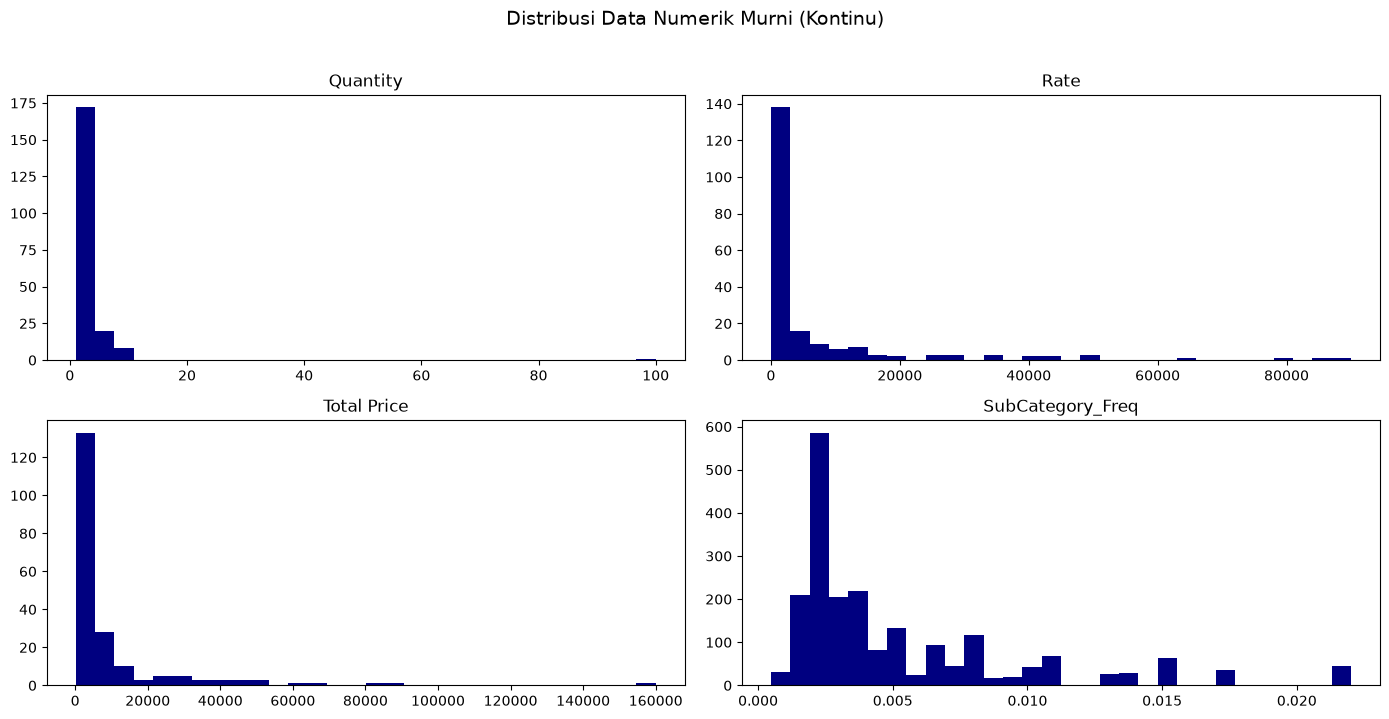

=== 2. PROPORSI DATA KATEGORI (HASIL ENCODING) ===


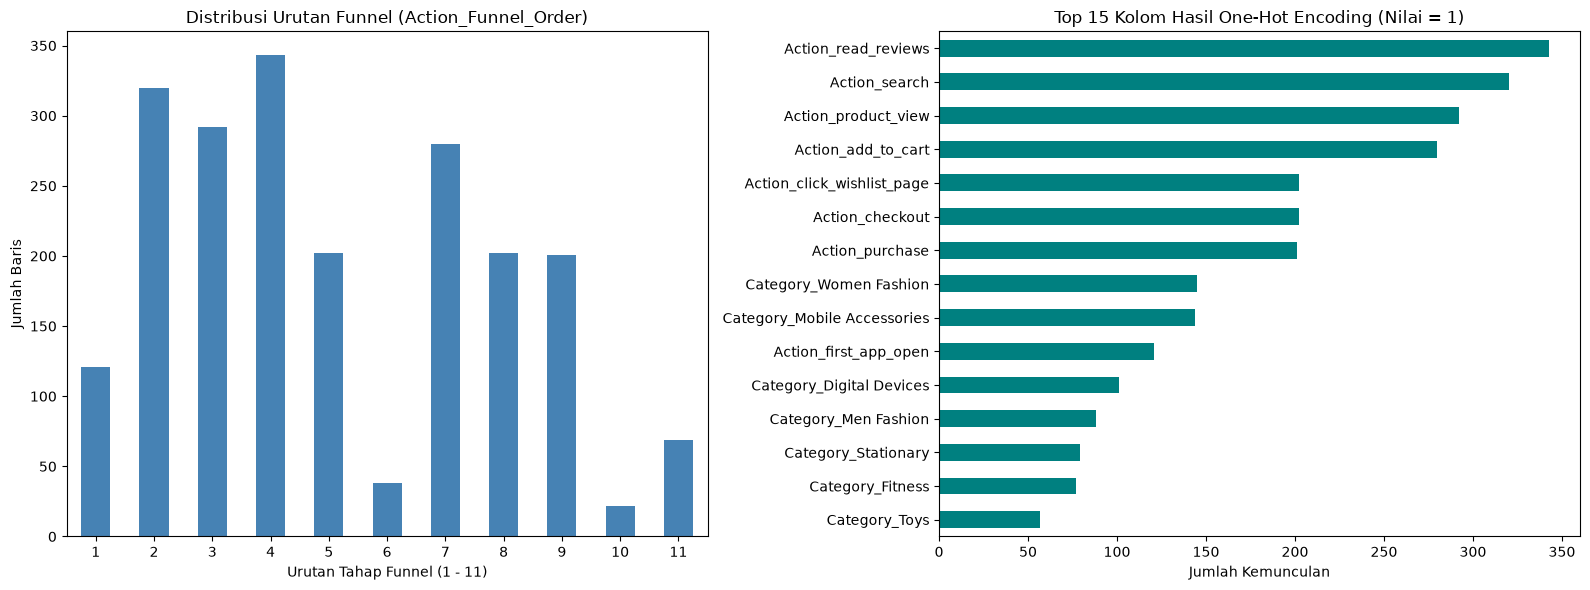

In [38]:
# 1. Ambil kolom numerik dan buang User_id
numeric_df = df_encode.select_dtypes(include=["number"]).drop(
    columns=["User_id"], errors="ignore"
)

# 2. Pisahkan kolom berdasarkan jenis fiturnya secara eksplisit
continuous_cols = ["Quantity", "Rate", "Total Price", "SubCategory_Freq"]
continuous_cols = [c for c in continuous_cols if c in numeric_df.columns]

ordinal_cols = ["Action_Funnel_Order"]
ordinal_cols = [c for c in ordinal_cols if c in numeric_df.columns]

# Kolom hasil One-Hot Encoding (biner 0 dan 1)
ohe_cols = [
    c for c in numeric_df.columns if c not in continuous_cols + ordinal_cols
]

# ==========================================
# VISUALISASI 1: NUMERIK MURNI (KONTINU)
# ==========================================
print("=== 1. DISTRIBUSI KOLOM NUMERIK KONTINU ===")
numeric_df[continuous_cols].hist(
    color="navy", figsize=(14, 7), bins=30, grid=False
)
plt.suptitle("Distribusi Data Numerik Murni (Kontinu)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ==========================================
# VISUALISASI 2: ORDINAL & PROPORSI ONE-HOT ENCODING
# ==========================================
print("=== 2. PROPORSI DATA KATEGORI (HASIL ENCODING) ===")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot Kiri: Distribusi urutan funnel (Ordinal)
if ordinal_cols:
    numeric_df["Action_Funnel_Order"].value_counts().sort_index().plot(
        kind="bar", ax=axes[0], color="steelblue"
    )
    axes[0].set_title("Distribusi Urutan Funnel (Action_Funnel_Order)", fontsize=12)
    axes[0].set_xlabel("Urutan Tahap Funnel (1 - 11)")
    axes[0].set_ylabel("Jumlah Baris")
    axes[0].tick_params(axis="x", rotation=0)

# Subplot Kanan: Top 15 fitur hasil One-Hot Encoding dengan frekuensi tertinggi
top_ohe = numeric_df[ohe_cols].sum().sort_values(ascending=True).tail(15)
top_ohe.plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Top 15 Kolom Hasil One-Hot Encoding (Nilai = 1)", fontsize=12)
axes[1].set_xlabel("Jumlah Kemunculan")

plt.tight_layout()
plt.show()

<b>Hasil Pengamatan</b>
<p>Setelah pembersihan data, seluruh aktivitas Action_Funnel_Order terpetakan utuh pada tahap 1–11 dengan dominasi tahap pra-pembelian (read_reviews, search, product_view, add_to_cart), sementara kategori terbanyak ditempati oleh Women Fashion dan Mobile Accessories. Pada variabel numerik kontinu, Quantity, Rate, dan Total Price menunjukkan kemiringan positif (right-skewed) pada nilai rendah disertai keberadaan outlier, sedangkan SubCategory_Freq menumpuk di kisaran 0,002–0,004.</p>
<p>Dari sisi analisis dan bisnis, pertahankan seluruh nilai transaksi beserta outlier-nya tanpa penghapusan karena merepresentasikan segmen pembeli bernilai tinggi (high-value dan pembelian grosir), serta gunakan median bersama IQR sebagai pendamping rata-rata saat melaporkan nilai transaksi tipikal. Selain itu, lakukan segmentasi khusus terhadap transaksi bernilai besar tersebut dan evaluasi hambatan pengguna dari tahap add_to_cart menuju checkout pada kategori unggulan Women Fashion dan Mobile Accessories guna meningkatkan konversi pembelian.</p>

<h4> 6.  Cek Outlier Numerikal</h4>

In [41]:
# 1. OTOMATISASI: Mengambil kolom numerik langsung dari df_clean (Sangat Aman)
all_numeric_cols = df_clean.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()

# 2. PENGECUALIAN: Hanya membuang ID dan Flag
kolom_dikecualikan = ['Transaction_ID', 'Invoice_ID', 'Loyalty_Flag']
kolom_kontinu = [col for col in all_numeric_cols if col not in kolom_dikecualikan]

# ============================================
# SUMMARY OUTLIER CHECK (IQR) PADA METRIK BISNIS (DF_CLEAN)
# ============================================
outlier_data = []

for col in kolom_kontinu:
    data_col = df_clean[col].dropna()
    
    q1 = data_col.quantile(0.25)
    q3 = data_col.quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    n_outliers = ((data_col < lower) | (data_col > upper)).sum()
    pct_outliers = (n_outliers / len(data_col)) * 100
    
    outlier_data.append({
        'Kolom': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Jumlah Outlier': n_outliers,
        'Persentase (%)': round(pct_outliers, 2)
    })

# Tampilkan dalam bentuk dataframe yang terurut dari outlier terbanyak
df_outlier_summary = pd.DataFrame(outlier_data).sort_values(by='Jumlah Outlier', ascending=False).reset_index(drop=True)
display(df_outlier_summary)

,Kolom,Q1,Q3,IQR,Jumlah Outlier,Persentase (%)
0,Rate,500.0,6000.0,5500.0,29,14.43
1,Total Price,1000.0,8000.0,7000.0,29,14.43
2,Quantity,1.0,3.0,2.0,11,5.47


<b>Hasil Pengamatan</b>
<p>Berdasarkan tabel deteksi outlier metode IQR, kolom Rate (Q1 = 500,0; Q3 = 6.000,0; IQR = 5.500,0) dan Total Price (Q1 = 1.000,0; Q3 = 8.000,0; IQR = 7.000,0) masing-masing mencatat 29 outlier atau sebesar 14,43%. Sementara itu, kolom Quantity memiliki sebaran antarkuartil yang sempit pada 1,0 hingga 3,0 unit (IQR = 2,0) dengan 11 outlier atau 5,47%, yang menunjukkan bahwa sebagian besar transaksi didominasi pembelian ritel berskala kecil.</p>
<p>Pertahankan seluruh outlier tersebut tanpa penghapusan dan kelompokkan ke dalam segmen pembeli bernilai tinggi (high-value maupun grosir) untuk penawaran program loyalitas atau paket bundel khusus, karena dalam transaksi e-commerce di dunia nyata keberadaan pembelian produk mahal dan pesanan partai besar merupakan perilaku bisnis yang wajar sekaligus kontributor utama pendapatan.</p>

<h4> 7. Cek Outlier Kategorikal</h4>

In [49]:
#OTOMATISASI: Ambil kolom kategorikal/teks murni dari df_clean
kolom_kategorikal = df_clean.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# 2. PENGECUALIAN: Buang ID
kolom_dikecualikan = ['Session_id', 'User_id']
kolom_kategorikal = [col for col in kolom_kategorikal if col not in kolom_dikecualikan]

# ============================================
# SUMMARY EKSTREM KATEGORIKAL (PALING BANYAK & PALING SEDIKIT)
# ============================================
proporsi_data = []
jumlah_tampil = 5  # Ambil 5 teratas & 5 terbawah per kolom (ubah sesuai kebutuhan)

for col in kolom_kategorikal:
    counts = df_clean[col].value_counts(dropna=False)
    pcts = df_clean[col].value_counts(normalize=True, dropna=False) * 100
    total_unik = len(counts)
    
    for idx, (kategori_item, count_val) in enumerate(counts.items()):
        pct_val = pcts[kategori_item]
        
        # Tandai hanya yang paling banyak (Top N) dan paling sedikit (Bottom N)
        if idx < jumlah_tampil:
            status = "Paling Banyak"
        elif idx >= total_unik - jumlah_tampil:
            status = "Paling Sedikit"
        else:
            status = "Normal"
            
        proporsi_data.append({
            'Nama Kolom': col,
            'Nilai Kategori': kategori_item,
            'Frekuensi': count_val,
            'Proporsi (%)': round(pct_val, 2),
            'Status': status
        })

# 3. FILTER & OUTPUT: Sembunyikan status 'Normal'
df_proporsi_kategori = pd.DataFrame(proporsi_data)
df_ekstrem = (
    df_proporsi_kategori[df_proporsi_kategori['Status'] != 'Normal']
    .sort_values(by=['Nama Kolom', 'Frekuensi'], ascending=[True, False])
    .reset_index(drop=True)
)

display(df_ekstrem)

,Nama Kolom,Nilai Kategori,Frekuensi,Proporsi (%),Status
0,Action,read_reviews,343,16.41,Paling Banyak
1,Action,search,320,15.31,Paling Banyak
2,Action,product_view,292,13.97,Paling Banyak
3,Action,add_to_cart,280,13.40,Paling Banyak
4,Action,checkout,202,9.67,Paling Banyak
5,Action,purchase,201,9.62,Paling Sedikit
6,Action,first_app_open,121,5.79,Paling Sedikit
7,Action,add_review,69,3.30,Paling Sedikit
8,Action,add_to_wishlist,38,1.82,Paling Sedikit
9,Action,product_review,22,1.05,Paling Sedikit


<b>Hasil Pengamatan</b>
<p>Berdasarkan tabel proporsi kategorikal, kolom Action didominasi oleh aktivitas pra-pembelian seperti read_reviews (16,41%), search (15,31%), product_view (13,97%), dan add_to_cart (13,40%) sebelum menyusut pada tahap checkout (9,67%), purchase (9,62%), serta interaksi pasca-pembelian seperti add_review (3,30%) dan product_review (1,05%). Pada sisi produk, distribusi Category dan SubCategory membentuk pola long-tail di mana interaksi terkonsentrasi pada kategori utama seperti Women Fashion (6,94%) dan Mobile Accessories (6,89%) serta subkategori Books (2,20%) dan Watches (1,72%), sedangkan item spesifik seperti Utilities dan Movies (0,10%) maupun Soft Toys hingga Thermometer (0,05%) hanya muncul 1 hingga 2 kali.</p>

<p>Pertahankan kategori minoritas tersebut tanpa penghapusan karena pola long-tail pada variasi ratusan SKU merupakan kondisi yang realistis dalam katalog e-commerce ritel di dunia nyata, sekaligus fokuskan anggaran promosi dan penyederhanaan alur dari add_to_cart menuju checkout pada kategori dengan trafik tertinggi (Women Fashion, Mobile Accessories, dan Books) untuk memaksimalkan konversi penjualan.</p>

<h4> 8. Feature Engineering</h4>

In [75]:
# 1. Ekstraksi Fitur Waktu
df_clean['Month_Num'] = df_clean['DateTime'].dt.month
df_clean['Month_Name'] = df_clean['DateTime'].dt.month_name()
df_clean['Day_Name'] = df_clean['DateTime'].dt.day_name()

jam = df_clean['DateTime'].dt.hour
df_clean['Time_Period'] = np.select(
    [(jam >= 5) & (jam <= 11), (jam >= 12) & (jam <= 15), (jam >= 16) & (jam <= 18)],
    ['Morning (05-11)', 'Afternoon (12-15)', 'Evening (16-18)'],
    default='Night (19-04)'
)

# 2. Segmentasi Pengguna (Buyer vs Non-Buyer)
daftar_buyer = df_clean.loc[df_clean['Action'] == 'purchase', 'User_id'].unique()
df_clean['User_Status'] = np.where(df_clean['User_id'].isin(daftar_buyer), 'Buyer', 'Non-Buyer')

# 3. Segmentasi Nilai Transaksi (mengikuti batas atas IQR = 18.500)
df_clean['Order_Segment'] = np.select(
    [df_clean['Total Price'] > 18500, df_clean['Total Price'].notna()],
    ['High-Value (Outlier)', 'Regular'],
    default='Non-Purchase'
)
# 4. Mapping urutan tahapan utama funnel (1 s.d. 6, aksi lainnya diberi kode 99)
funnel_step_map = {
    'search': 1,
    'product_view': 2,
    'read_reviews': 3,
    'add_to_cart': 4,
    'checkout': 5,
    'purchase': 6
}
df_clean['Funnel_Step'] = df_clean['Action'].map(funnel_step_map).fillna(99).astype(int)

# 5. Mapping label rapi untuk tampilan visual Funnel Chart di Power BI
funnel_stage_map = {
    'search': 'Search',
    'product_view': 'Product View',
    'read_reviews': 'Read Reviews',
    'add_to_cart': 'Add to Cart',
    'checkout': 'Checkout',
    'purchase': 'Purchase'
}
df_clean['Funnel_Stage'] = df_clean['Action'].map(funnel_stage_map).fillna('Other')

# Cek hasil pemetaan
display(df_clean[['Action', 'Funnel_Step', 'Funnel_Stage']].value_counts().reset_index(name='Jumlah').sort_values('Funnel_Step'))

,Action,Funnel_Step,Funnel_Stage,Jumlah
1,search,1,Search,320
2,product_view,2,Product View,292
0,read_reviews,3,Read Reviews,343
3,add_to_cart,4,Add to Cart,280
4,checkout,5,Checkout,202
6,purchase,6,Purchase,201
5,click_wishlist_page,99,Other,202
7,first_app_open,99,Other,121
8,add_review,99,Other,69
9,add_to_wishlist,99,Other,38


<h3>E. EDA (Exploratory Data Analysis)</h3>

<h4> 1. Univariate Analysis</h4>

<h5> 1.1 Distribusi Variabel Numerik</h5>

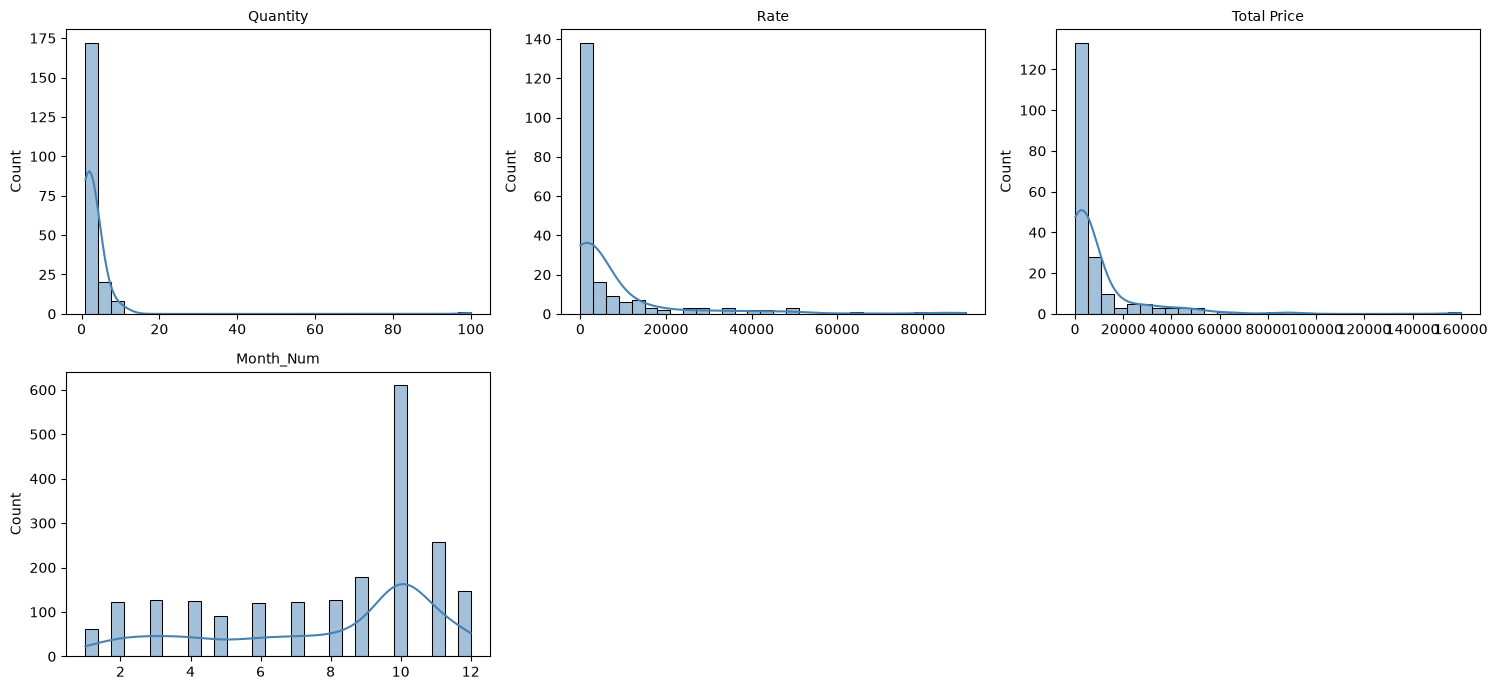

UJI NORMALITAS (df_clean) - Kolmogorov-Smirnov Test


,kolom,ks_statistic,p_value,skewness,kurtosis,distribusi_normal
0,Quantity,0.3919,2.526167e-28,12.497,166.362,Tidak
1,Rate,0.3149,3.251461e-18,3.319,12.115,Tidak
2,Total Price,0.3047,4.644338e-17,4.276,25.480,Tidak
3,Month_Num,0.2286,1.755128e-96,-0.710,-0.792,Tidak



Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)



In [55]:
# ============================================
# 0. OTOMATISASI DETEKSI KOLOM NUMERIK (df_clean)
# ============================================
numeric_cols = df_clean.select_dtypes(include=['int64', 'float64', 'int32', 'Int64']).columns.tolist()

# Pengecualian kolom ID / Flag yang tidak relevan diuji distribusinya
kolom_dikecualikan = ['User_id', 'Session_ID']
numeric_cols_to_check = [col for col in numeric_cols if col not in kolom_dikecualikan]

# ============================================
# 1. SUBPLOT DISTRIBUSI (HISTOGRAM) SEMUA KOLOM SEKALIGUS
# ============================================
n_cols = 3
n_rows = -(-len(numeric_cols_to_check) // n_cols)  # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols_to_check):
    data_plot = df_clean[col].dropna()
    sns.histplot(data_plot, kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')

# Matikan subplot kosong jika jumlah kolom tidak pas dengan grid
for j in range(len(numeric_cols_to_check), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('distribusi_semua_kolom_fmcg.png', dpi=100, bbox_inches='tight')
plt.show()

# ============================================
# 2. UJI NORMALITAS - KOLMOGOROV-SMIRNOV (df_clean)
# ============================================
print("="*80)
print("UJI NORMALITAS (df_clean) - Kolmogorov-Smirnov Test")
print("="*80)

results = []
for col in numeric_cols_to_check:
    data = df_clean[col].dropna()
    
    # Standardisasi dulu (z-score) karena K-S butuh dibandingkan ke distribusi normal standar
    data_standardized = (data - data.mean()) / data.std()
    ks_stat, p_value = stats.kstest(data_standardized, 'norm')
    skewness = stats.skew(data)
    kurtosis = stats.kurtosis(data)  # excess kurtosis (0 = normal)

    results.append({
        'kolom': col,
        'ks_statistic': round(ks_stat, 4),
        'p_value': p_value,
        'skewness': round(skewness, 3),
        'kurtosis': round(kurtosis, 3),
        'distribusi_normal': 'Tidak' if p_value < 0.05 else 'Ya'
    })

df_normality = pd.DataFrame(results)
display(df_normality)

print("""
Interpretasi:
- p_value < 0.05 -> secara statistik BUKAN distribusi normal (pasti terjadi pada n = 100.000 karena ukuran sampel besar)
- skewness mendekati 0 -> distribusi cenderung simetris
  (positif = ekor panjang ke kanan / right-skewed, negatif = ekor panjang ke kiri / left-skewed)
- kurtosis mendekati 0 -> bentuk puncak mendekati normal
  (positif = lebih "runcing"/heavy-tailed, negatif = distribusi lebih datar / platykurtic)
""")

<b>Hasil Pengamatan</b>
<p>Berdasarkan histogram dan uji normalitas Kolmogorov-Smirnov, variabel Quantity (skewness = 12,497; kurtosis = 166,362; p=2,53×10−28
p=2,53×10−28), Rate (skewness = 3,319; kurtosis = 12,115; p=3,25×10−18
p=3,25×10−18), dan Total Price (skewness = 4,276; kurtosis = 25,480; p=4,64×10−17
p=4,64×10−17) seluruhnya tidak berdistribusi normal karena nilai p<0,05
p<0,05. Ketiga variabel transaksi tersebut menampilkan kurva dengan kemiringan positif (right-skewed) yang menumpuk pada nilai rendah disertai ekor panjang ke kanan akibat keberadaan outlier pada kuantitas hingga 100 unit dan total belanja mencapai 160.000.</p>

<h5> 1.2 Distribusi Variabel Kategorikal</h5>

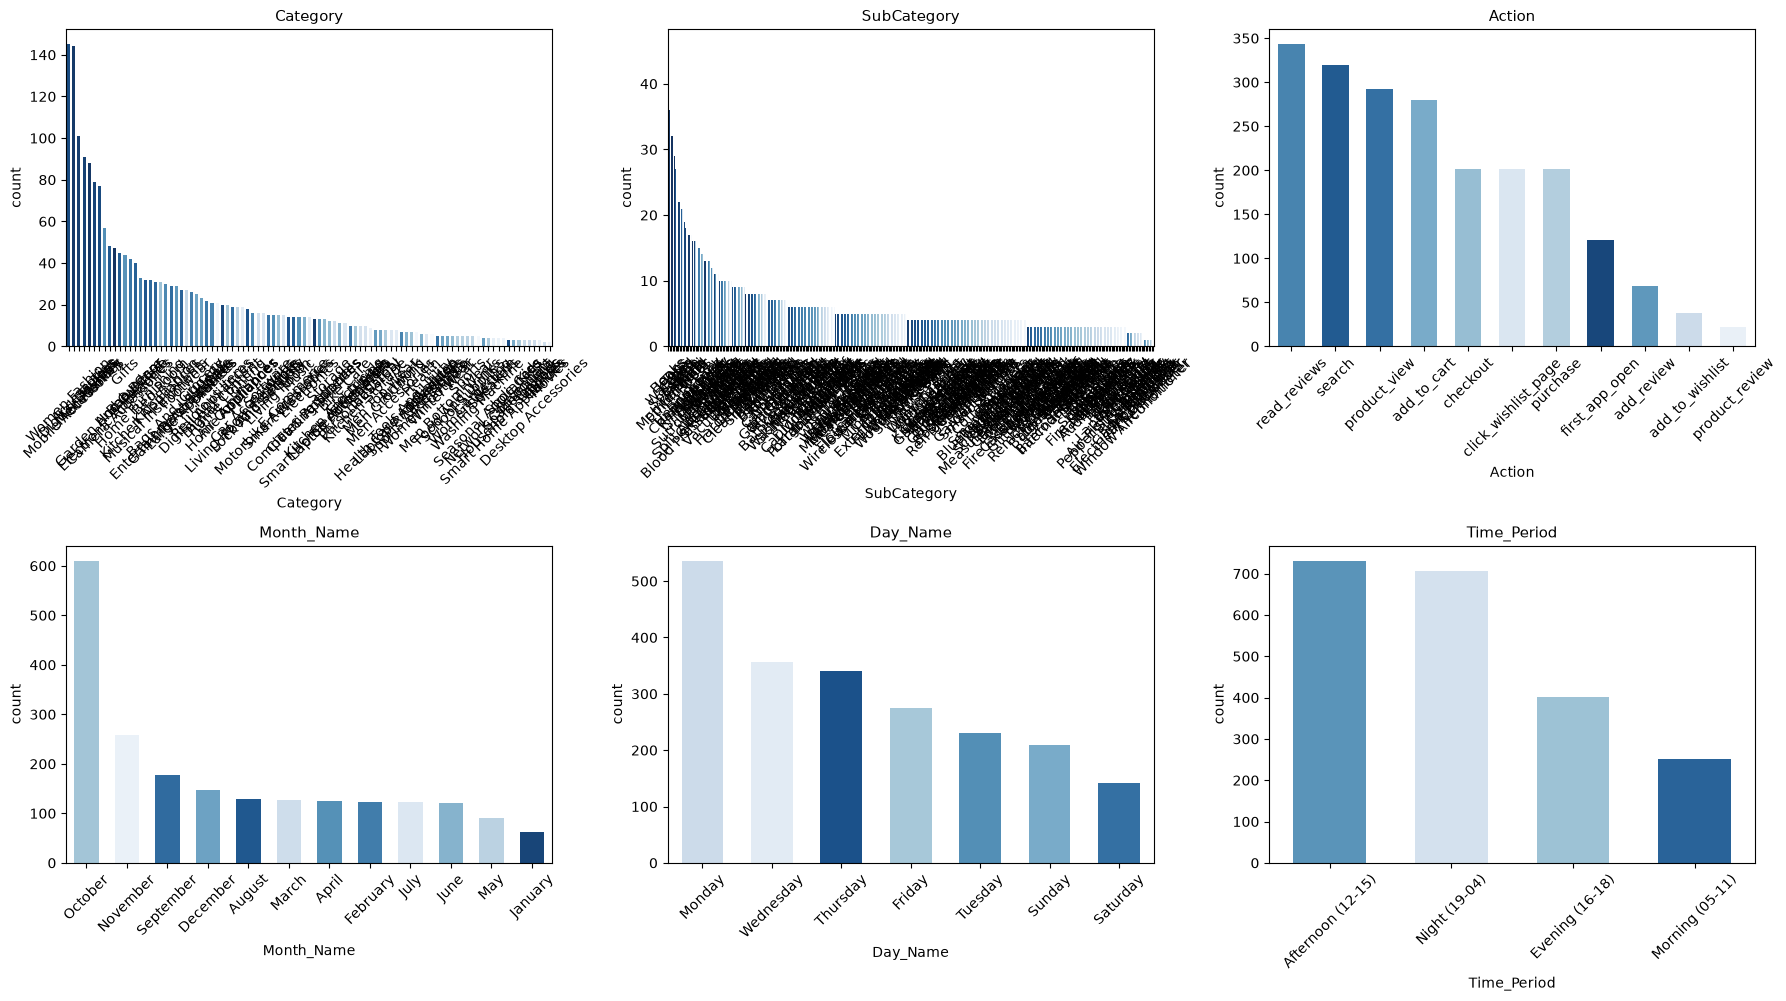

In [66]:
categorical_cols = [
    'Category', 'SubCategory', 'Action', 'Month_Name',
    'Day_Name', 'Time_Period'
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df_clean[col].value_counts().index if not (df_clean[col].dtype.name == 'category' and df_clean[col].cat.ordered) else None
    sns.countplot(
        data=df_clean, 
        x=col, 
        ax=axes[i], 
        order=order, 
        hue=col, 
        dodge=False,       
        width=0.6,         
        palette='Blues_r', 
        legend=False
    )
    
    axes[i].set_title(col, fontsize=11)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [63]:
# ==========================================================
# DISTRIBUSI VARIABEL KATEGORIKAL
# ==========================================================

for col in categorical_cols:
    print("="*80)
    print(f"DISTRIBUSI : {col.upper()}")
    print("="*80)

    freq = df_clean[col].value_counts()
    percent = df_clean[col].value_counts(normalize=True) * 100

    summary = pd.DataFrame({
        "Count": freq,
        "Percentage (%)": percent.round(2)
    })

    display(summary)

DISTRIBUSI : CATEGORY


,Count,Percentage (%)
Category,,
Women Fashion,145,6.94
Mobile Accessories,144,6.89
Digital Devices,101,4.83
Accessories,91,4.35
Men Fashion,88,4.21
...,...,...
Kids,3,0.14
Desktop Accessories,3,0.14
Laptops,3,0.14


DISTRIBUSI : SUBCATEGORY


,Count,Percentage (%)
SubCategory,,
Books,46,2.20
Watches,36,1.72
Jeans,32,1.53
Mobile Phone,32,1.53
Speakers,29,1.39
...,...,...
Soft Toys,1,0.05
Drone,1,0.05
Umbrella,1,0.05


DISTRIBUSI : ACTION


,Count,Percentage (%)
Action,,
read_reviews,343,16.41
search,320,15.31
product_view,292,13.97
add_to_cart,280,13.40
checkout,202,9.67
click_wishlist_page,202,9.67
purchase,201,9.62
first_app_open,121,5.79
add_review,69,3.30


... (6 outputs left out)

DISTRIBUSI : USER_STATUS


,Count,Percentage (%)
User_Status,,
Buyer,1303,62.34
Non-Buyer,787,37.66


DISTRIBUSI : ORDER_SEGMENT


,Count,Percentage (%)
Order_Segment,,
Non-Purchase,1889,90.38
Regular,172,8.23
High-Value (Outlier),29,1.39


=== 1. TOP 10 CATEGORY BERDASARKAN REVENUE & OUTLIER (> 18.500) ===


,Category,Jumlah_Transaksi,Total_Revenue,Median_Total_Price,Total_Quantity,Jumlah_Outlier_HighValue
62,Tablets,2,225000.0,112500.0,3,2
67,Women Fashion,13,132550.0,5000.0,36,2
47,Mobile Accessories,15,128700.0,1250.0,35,2
14,Digital Devices,7,121800.0,8000.0,18,3
38,Laptop And Desktop,1,90000.0,90000.0,1,1
65,Tv & Appliances,1,85000.0,85000.0,1,1
0,Accessories,12,76650.0,3500.0,22,1
18,Entertainment Systems,4,74400.0,17200.0,6,2
31,Home Furnishing,4,73500.0,16000.0,5,2
13,Digital Appliances,2,65000.0,32500.0,2,1



=== 2. MONTH_NAME VS TOTAL PRICE & ACTION ===


,Month_Num,Month_Name,Total_Aktivitas,Total_Search,Total_Purchase,Conversion_Rate_Pct,Total_Revenue
0,1,January,62,13,4,6.45,24800.0
1,2,February,123,23,7,5.69,38700.0
2,3,March,127,19,11,8.66,97100.0
3,4,April,124,25,11,8.87,98400.0
4,5,May,90,13,9,10.00,105000.0
5,6,June,120,20,13,10.83,150850.0
6,7,July,123,10,14,11.38,68850.0
7,8,August,128,23,12,9.38,46450.0
8,9,September,178,23,14,7.87,139250.0
9,10,October,610,97,56,9.18,602700.0



=== 3A. DAY_NAME VS ACTION & REVENUE ===


,Day_Name,Total_Aktivitas,Total_Add_To_Cart,Total_Checkout,Total_Purchase,Conversion_Rate_Pct,Total_Revenue
0,Monday,536,73,51,51,9.51,343730.0
1,Tuesday,231,30,25,25,10.82,249900.0
2,Wednesday,356,49,35,33,9.27,278850.0
3,Thursday,341,47,35,37,10.85,341300.0
4,Friday,275,38,29,27,9.82,337700.0
5,Saturday,142,18,11,12,8.45,75800.0
6,Sunday,209,25,16,16,7.66,273250.0


... (2 outputs left out)


=== 4A. USER_STATUS VS ACTION (FREKUENSI & PROPORSI %) ===


User_Status,Buyer,Non-Buyer,Buyer_Pct,Non-Buyer_Pct
Action,,,,
purchase,201,0,15.43,0.00
checkout,198,4,15.20,0.51
add_to_cart,187,93,14.35,11.82
search,185,135,14.20,17.15
read_reviews,171,172,13.12,21.86
product_view,142,150,10.90,19.06
click_wishlist_page,84,118,6.45,14.99
add_review,51,18,3.91,2.29
first_app_open,39,82,2.99,10.42



=== 4B. USER_STATUS VS TOP 10 CATEGORY ===


User_Status,Buyer,Non-Buyer
Category,,
Mobile Accessories,116,28
Women Fashion,101,44
Accessories,71,20
Men Fashion,65,23
Stationary,60,19
Fitness,56,21
Digital Devices,56,45
Toys,45,12
Gifts,44,0


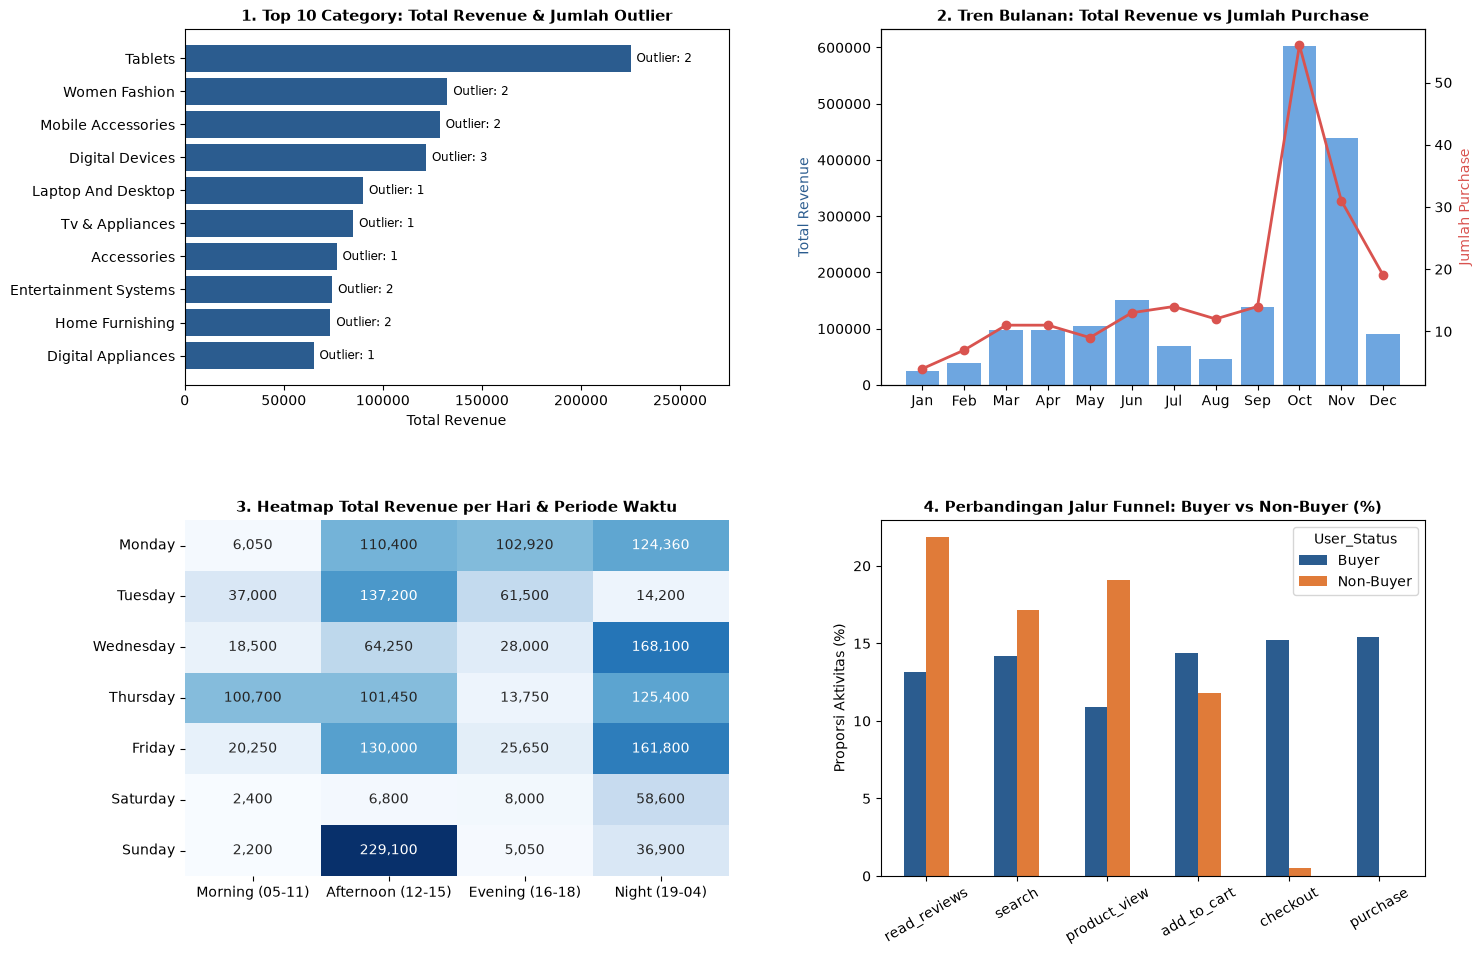

In [67]:
# ==============================================================================
# 1. Category vs Total Price & Quantity (Khusus Transaksi Purchase)
# ==============================================================================
df_pur = df_clean[df_clean['Action'] == 'purchase'].copy()

cat_biv = (
    df_pur.groupby('Category', as_index=False)
    .agg(
        Jumlah_Transaksi=('Total Price', 'count'),
        Total_Revenue=('Total Price', 'sum'),
        Median_Total_Price=('Total Price', 'median'),
        Total_Quantity=('Quantity', 'sum'),
        Jumlah_Outlier_HighValue=('Order_Segment', lambda x: (x == 'High-Value (Outlier)').sum())
    )
    .sort_values(by='Total_Revenue', ascending=False)
)

print("=== 1. TOP 10 CATEGORY BERDASARKAN REVENUE & OUTLIER (> 18.500) ===")
display(cat_biv.head(10))

# ==============================================================================
# 2. Month_Name vs Total Price & Action
# ==============================================================================
month_biv = (
    df_clean.groupby(['Month_Num', 'Month_Name'], as_index=False)
    .agg(
        Total_Aktivitas=('Action', 'count'),
        Total_Search=('Action', lambda x: (x == 'search').sum()),
        Total_Purchase=('Action', lambda x: (x == 'purchase').sum()),
        Conversion_Rate_Pct=('Action', lambda x: round((x == 'purchase').mean() * 100, 2)),
        Total_Revenue=('Total Price', 'sum')
    )
    .sort_values('Month_Num')
)

print("\n=== 2. MONTH_NAME VS TOTAL PRICE & ACTION ===")
display(month_biv)

# ==============================================================================
# 3. Day_Name & Time_Period vs Action (purchase)
# ==============================================================================
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_biv = (
    df_clean.groupby('Day_Name')
    .agg(
        Total_Aktivitas=('Action', 'count'),
        Total_Add_To_Cart=('Action', lambda x: (x == 'add_to_cart').sum()),
        Total_Checkout=('Action', lambda x: (x == 'checkout').sum()),
        Total_Purchase=('Action', lambda x: (x == 'purchase').sum()),
        Conversion_Rate_Pct=('Action', lambda x: round((x == 'purchase').mean() * 100, 2)),
        Total_Revenue=('Total Price', 'sum')
    )
    .reindex(day_order)
    .reset_index()
)

time_order = ['Morning (05-11)', 'Afternoon (12-15)', 'Evening (16-18)', 'Night (19-04)']
time_biv = (
    df_clean.groupby('Time_Period')
    .agg(
        Total_Aktivitas=('Action', 'count'),
        Total_Add_To_Cart=('Action', lambda x: (x == 'add_to_cart').sum()),
        Total_Checkout=('Action', lambda x: (x == 'checkout').sum()),
        Total_Purchase=('Action', lambda x: (x == 'purchase').sum()),
        Conversion_Rate_Pct=('Action', lambda x: round((x == 'purchase').mean() * 100, 2)),
        Total_Revenue=('Total Price', 'sum')
    )
    .reindex(time_order)
    .reset_index()
)

print("\n=== 3A. DAY_NAME VS ACTION & REVENUE ===")
display(day_biv)
print("\n=== 3B. TIME_PERIOD VS ACTION & REVENUE ===")
display(time_biv)

# ==============================================================================
# 4. User_Status (Buyer vs Non-Buyer) vs Action & Category
# ==============================================================================
user_action_cnt = pd.crosstab(df_clean['Action'], df_clean['User_Status'])
user_action_pct = pd.crosstab(df_clean['Action'], df_clean['User_Status'], normalize='columns') * 100
user_action_biv = pd.concat([user_action_cnt, user_action_pct.round(2).add_suffix('_Pct')], axis=1)

print("\n=== 4A. USER_STATUS VS ACTION (FREKUENSI & PROPORSI %) ===")
display(user_action_biv.sort_values(by='Buyer', ascending=False))

user_cat_biv = pd.crosstab(df_clean['Category'], df_clean['User_Status'])
print("\n=== 4B. USER_STATUS VS TOP 10 CATEGORY ===")
display(user_cat_biv.sort_values(by='Buyer', ascending=False).head(10))

# ==============================================================================
# VISUALISASI 4 PANEL ANALISIS BIVARIAT
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.38, wspace=0.28)

# Panel 1: Top 10 Category by Revenue & Jumlah Outlier
top10_cat = cat_biv.head(10).sort_values('Total_Revenue', ascending=True)
axes[0, 0].barh(top10_cat['Category'], top10_cat['Total_Revenue'], color='#2b5c8f')
axes[0, 0].set_title('1. Top 10 Category: Total Revenue & Jumlah Outlier', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Total Revenue')
for idx, row in enumerate(top10_cat.itertuples()):
    axes[0, 0].text(row.Total_Revenue + 3000, idx, f"Outlier: {row.Jumlah_Outlier_HighValue}", va='center', fontsize=8.5)
axes[0, 0].set_xlim(0, top10_cat['Total_Revenue'].max() * 1.22)

# Panel 2: Tren Bulanan Revenue vs Purchase
ax2 = axes[0, 1]
ax2_twin = ax2.twinx()
ax2.bar(month_biv['Month_Name'].str[:3], month_biv['Total_Revenue'], color='#4a90d9', alpha=0.8)
ax2_twin.plot(month_biv['Month_Name'].str[:3], month_biv['Total_Purchase'], color='#d9534f', marker='o', linewidth=2)
ax2.set_title('2. Tren Bulanan: Total Revenue vs Jumlah Purchase', fontsize=11, fontweight='bold')
ax2.set_ylabel('Total Revenue', color='#2b5c8f')
ax2_twin.set_ylabel('Jumlah Purchase', color='#d9534f')

# Panel 3: Heatmap Revenue per Day_Name & Time_Period
pivot_day_time = df_pur.pivot_table(
    index='Day_Name', columns='Time_Period', values='Total Price', aggfunc='sum', fill_value=0
).reindex(index=day_order, columns=time_order)
sns.heatmap(pivot_day_time, annot=True, fmt=',.0f', cmap='Blues', ax=axes[1, 0], cbar=False)
axes[1, 0].set_title('3. Heatmap Total Revenue per Hari & Periode Waktu', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('')

# Panel 4: Perbandingan Jalur Funnel Buyer vs Non-Buyer (%)
urutan_funnel = ['read_reviews', 'search', 'product_view', 'add_to_cart', 'checkout', 'purchase']
user_action_pct.loc[urutan_funnel].plot(kind='bar', ax=axes[1, 1], color=['#2b5c8f', '#e07b39'])
axes[1, 1].set_title('4. Perbandingan Jalur Funnel: Buyer vs Non-Buyer (%)', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Proporsi Aktivitas (%)')
axes[1, 1].set_xlabel('')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.show()

<b>Hasil Pengamatan</b>
<p><b>Kategori (Category):</b> Tablets meraih pendapatan tertinggi (225.000 hanya dari 2 transaksi outlier), sedangkan Mobile Accessories (15 transaksi, median 1.250) dan Women Fashion (13 transaksi, median 5.000) unggul dari sisi volume transaksi dan kuantitas (35–36 unit). <b>Bulanan (Month_Name):</b> Lonjakan Oktober (610 aktivitas) dan November (258 aktivitas) terbukti diikuti kenaikan pembelian nyata—Oktober mencatat 56 purchase (602.700) dan November 31 purchase (438.580, konversi 12,02%). <b>Hari & Waktu (Day_Name & Time_Period):</b> Night (19-04) memiliki rasio konversi tertinggi (11,33%; 80 purchase dari 81 checkout), sedangkan Afternoon (12-15) menyumbang pendapatan terbesar (779.200) dengan tingkat batal di keranjang (cart abandonment) lebih tinggi (89 add_to_cart &rarr; 59 purchase). <b>Status Pengguna (User_Status):</b> Kelompok Non-Buyer terjebak di tahap eksplorasi (read_reviews 21,86% dan product_view 19,06%), dan dari 93 kali add_to_cart yang mereka lakukan, hanya 4 kali yang berlanjut ke checkout tanpa satu pun selesai menjadi purchase.</p>
<b>Rekomendasi Tindakan (Actionable):</b>
<p><b>1. Optimalisasi Kategori Unggulan:</b> Terapkan strategi promosi khusus berupa bundel diskon (*bundling*) pada kategori <code style="background: #f1f5f9; padding: 2px 5px; border-radius: 4px;">Mobile Accessories</code> dan <code style="background: #f1f5f9; padding: 2px 5px; border-radius: 4px;">Women Fashion</code> untuk mendongkrak volume penjualan ritel, serta sediakan program loyalitas eksklusif untuk segmen transaksi *outlier* pada kategori <code style="background: #f1f5f9; padding: 2px 5px; border-radius: 4px;">Tablets</code>. <b>2. Kampanye Musim Puncak (Q4):</b> Alokasikan anggaran iklan dan stok inventaris secara maksimal pada bulan Oktober dan November untuk mengkapitalisasi lonjakan transaksi yang menyumbang lebih dari separuh pendapatan tahunan. <b>3. Personalisasi Waktu Penawaran:</b> Jadwalkan *push notification* atau *flash sale* pada rentang waktu sore hingga malam hari (pukul 12.00–15.00 dan 19.00–04.00) guna memaksimalkan tingginya konversi belanja dan menekan tingkat pembatalan di keranjang belanja. <b>4. Strategi Retensi Non-Buyer:</b> Lakukan intervensi berupa *email reminder* atau voucher diskon terbatas khusus bagi pengguna dalam kategori <code style="background: #f1f5f9; padding: 2px 5px; border-radius: 4px;">Non-Buyer</code> yang tertahan di tahap *add_to_cart* agar terdorong untuk melanjutkan transaksi ke tahap *checkout*.</p>

<b>Hasil Pengamatan</b>
<p><b>1. Kategori (Category):</b> <i>Tablets</i> meraih pendapatan tertinggi (225.000 hanya dari 2 transaksi <i>outlier</i>), sedangkan <i>Mobile Accessories</i> (15 transaksi, median 1.250) dan <i>Women Fashion</i> (13 transaksi, median 5.000) unggul dari sisi volume transaksi dan kuantitas (35–36 unit).</p>
<p><b>2. Bulanan (Month_Name):</b> Lonjakan Oktober (610 aktivitas) dan November (258 aktivitas) terbukti diikuti kenaikan pembelian nyata—Oktober mencatat 56 <i>purchase</i> (602.700) dan November 31 <i>purchase</i> (438.580, konversi 12,02%).</p>
<p><b>3. Hari &amp; Waktu (Day_Name &amp; Time_Period):</b> <i>Night</i> (19-04) memiliki rasio konversi tertinggi (11,33%; 80 <i>purchase</i> dari 81 <i>checkout</i>), sedangkan <i>Afternoon</i> (12-15) menyumbang pendapatan terbesar (779.200) dengan tingkat batal di keranjang (<i>cart abandonment</i>) lebih tinggi (89 <i>add_to_cart</i> &rarr; 59 <i>purchase</i>).</p>
<p><b>4. Status Pengguna (User_Status):</b> Kelompok <i>Non-Buyer</i> terjebak di tahap eksplorasi (<i>read_reviews</i> 21,86% dan <i>product_view</i> 19,06%), dan dari 93 kali <i>add_to_cart</i> yang mereka lakukan, hanya 4 kali yang berlanjut ke <i>checkout</i> tanpa satu pun selesai menjadi <i>purchase</i>.</p>

<b>Rekomendasi Tindakan (Actionable)</b>
<p><b>1. Optimalisasi Kategori Unggulan:</b> Terapkan strategi paket bundel diskon (<i>bundling</i>) pada kategori <i>Mobile Accessories</i> dan <i>Women Fashion</i> untuk mendongkrak volume penjualan ritel, serta sediakan program loyalitas eksklusif untuk segmen transaksi <i>outlier</i> pada kategori <i>Tablets</i>.</p>
<p><b>2. Kampanye Musim Puncak (Q4):</b> Alokasikan anggaran iklan dan stok inventaris secara maksimal pada bulan Oktober dan November untuk mengkapitalisasi lonjakan transaksi yang menyumbang lebih dari separuh pendapatan tahunan.</p>
<p><b>3. Personalisasi Waktu Penawaran:</b> Jadwalkan <i>push notification</i> atau <i>flash sale</i> pada rentang waktu siang hingga malam hari (pukul 12.00–15.00 dan 19.00–04.00) guna memaksimalkan tingginya konversi belanja sekaligus menekan pembatalan di keranjang.</p>
<p><b>4. Strategi Retensi Non-Buyer:</b> Lakukan intervensi berupa <i>email reminder</i> atau voucher diskon terbatas bagi pengguna dalam kelompok <i>Non-Buyer</i> yang tertahan di tahap <i>add_to_cart</i> agar terdorong menyelesaikan transaksi ke tahap <i>checkout</i>.</p>

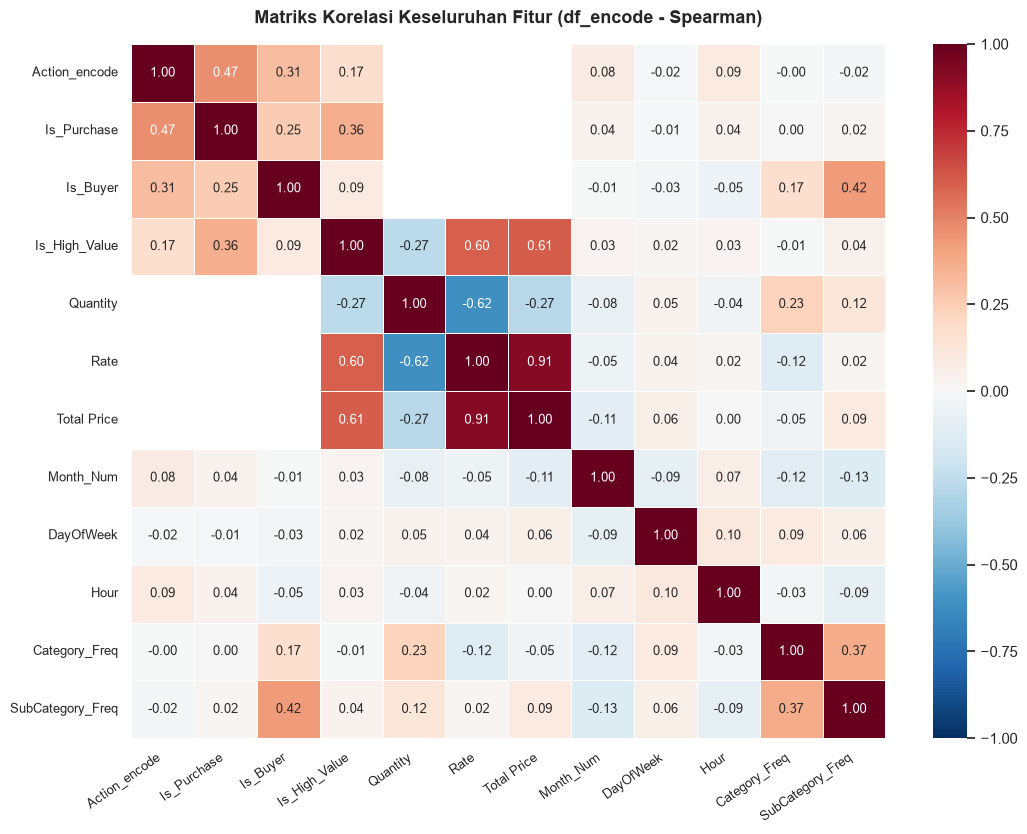

In [73]:
# ==========================================
# 1. ENCODING RAMPING PADA SATU DATASET UTUH (df_clean)
# ==========================================
df_encode = df_clean.copy()

# Urutan Funnel (Ordinal) & Flag Biner
funnel_mapping = {
    'first_app_open': 1, 'search': 2, 'product_view': 3, 'read_reviews': 4,
    'click_wishlist_page': 5, 'add_to_wishlist': 6, 'add_to_cart': 7,
    'checkout': 8, 'purchase': 9, 'product_review': 10, 'add_review': 11
}
df_encode['Action_encode'] = df_encode['Action'].map(funnel_mapping).fillna(0).astype(int)
df_encode['Is_Purchase'] = (df_encode['Action'] == 'purchase').astype(int)
df_encode['Is_Buyer'] = (df_encode['User_Status'] == 'Buyer').astype(int)
df_encode['Is_High_Value'] = (df_encode['Order_Segment'] == 'High-Value (Outlier)').astype(int)

# Ekstraksi fitur waktu numerik
df_encode['Month_Num'] = df_encode['DateTime'].dt.month
df_encode['DayOfWeek'] = df_encode['DateTime'].dt.dayofweek
df_encode['Hour'] = df_encode['DateTime'].dt.hour

# Frequency Encoding untuk Category (95 unik) & SubCategory (340+ unik)
df_encode['Category_Freq'] = df_encode['Category'].map(df_encode['Category'].value_counts(normalize=True))
df_encode['SubCategory_Freq'] = df_encode['SubCategory'].map(df_encode['SubCategory'].value_counts(normalize=True))

# ==========================================
# 2. PLOT SATU HEATMAP KESELURUHAN (12 x 12)
# ==========================================
kolom_korelasi = [
    'Action_encode', 'Is_Purchase', 'Is_Buyer', 'Is_High_Value',
    'Quantity', 'Rate', 'Total Price',
    'Month_Num', 'DayOfWeek', 'Hour', 'Category_Freq', 'SubCategory_Freq'
]

corr_matrix_full = df_encode[kolom_korelasi].corr(method='spearman')

plt.figure(figsize=(11, 8.5))
sns.set_theme(style="white")

sns.heatmap(
    corr_matrix_full,
    annot=True,
    fmt=".2f",
    cmap='RdBu_r',
    vmax=1, vmin=-1, center=0,
    linewidths=0.5,
    linecolor='white',
    annot_kws={"size": 9}
)

plt.title('Matriks Korelasi Keseluruhan Fitur (df_encode - Spearman)', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=35, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)

plt.tight_layout()
plt.show()

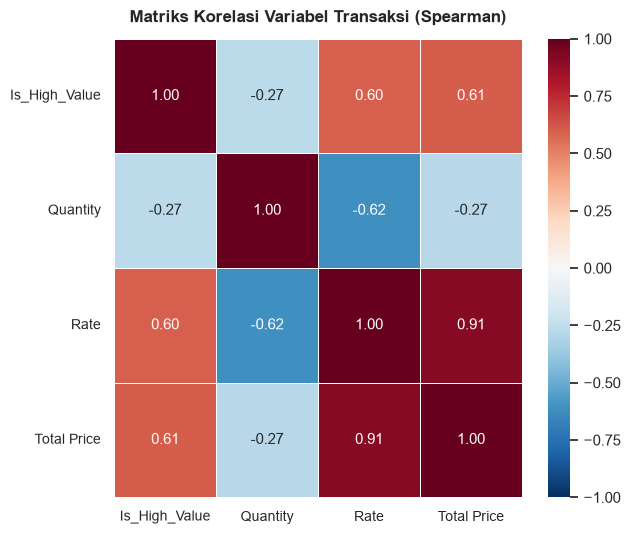

In [74]:
# Pastikan kolom Is_High_Value sudah tersedia di df_encode
df_encode['Is_High_Value'] = (df_clean['Order_Segment'] == 'High-Value (Outlier)').astype(int)

# Pilih hanya 4 kolom sesuai blok korelasi pada gambar
kolom_korelasi = ['Is_High_Value', 'Quantity', 'Rate', 'Total Price']
corr_matrix = df_encode[kolom_korelasi].corr(method='spearman')

# Plot Heatmap 4x4
plt.figure(figsize=(6.5, 5.5))
sns.set_theme(style="white")

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='RdBu_r',
    vmax=1, vmin=-1, center=0,
    linewidths=0.5,
    linecolor='white',
    annot_kws={"size": 11}
)

plt.title('Matriks Korelasi Variabel Transaksi (Spearman)', fontsize=12, fontweight='bold', pad=12)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

<b>Hasil Pengamatan</b>
<p>Berdasarkan matriks korelasi Spearman pada variabel transaksi, Total Price memiliki korelasi positif yang sangat kuat dengan harga satuan Rate (r=0,91
r=0,91) serta korelasi positif sedang dengan Is_High_Value (r=0,61
r=0,61), sementara hubungannya dengan Quantity justru bernilai negatif lemah (r=−0,27
r=−0,27). Sebaliknya, Quantity dan Rate menunjukkan korelasi negatif cukup kuat (r=−0,62
r=−0,62), yang menandakan bahwa transaksi bernilai besar lebih banyak didorong oleh harga per unit produk yang tinggi dibandingkan pembelian dalam kuantitas massal.</p>
<p>Fokuskan strategi upselling dan penawaran produk margin tinggi pada segmen pembeli yang mencari kategori bernilai mahal serta terapkan promo paket bundel pada produk berharga satuan rendah untuk meningkatkan volume belanja, karena pola konsumen membeli barang mahal secara satuan dan barang murah dalam jumlah banyak merupakan perilaku transaksi e-commerce yang realistis di dunia nyata.</p>

In [77]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 2090 entries, 0 to 2089
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   User_id        2090 non-null   str           
 1   Session_id     2090 non-null   str           
 2   DateTime       2090 non-null   datetime64[us]
 3   Category       2090 non-null   str           
 4   SubCategory    2090 non-null   str           
 5   Action         2090 non-null   str           
 6   Quantity       201 non-null    Int64         
 7   Rate           201 non-null    float64       
 8   Total Price    201 non-null    float64       
 9   Month_Num      2090 non-null   int32         
 10  Month_Name     2090 non-null   str           
 11  Day_Name       2090 non-null   str           
 12  Time_Period    2090 non-null   str           
 13  User_Status    2090 non-null   str           
 14  Order_Segment  2090 non-null   str           
 15  Funnel_Step    2090 non-null   i

In [78]:
# Export dataset bersih ke CSV (tanpa menyertakan index)
df_clean.to_excel('take_home_test.xlsx', sheet_name='customer_data', index=False)
print("Berhasil! Data siap diload ke Power BI.")

Berhasil! Data siap diload ke Power BI.
